# 高・中・低のベイジアンネットワークを業務部門に説明する
## Python / pgmpy 実行版

目的は、**構造・条件付き確率・関係の強さについて、どの根拠まで示せるかを検証すること**です。
正解のネットワークを当てた割合は評価しません。既存の `df` があればそのコピーを使用し、ない場合だけ1,200行×5列のサンプルを生成します。

このNotebookは **Python (bn)** カーネルで上から実行します。pgmpy 1.1.2の新しいAPIで構造学習・パラメータ学習を行います。Rは使用しません。
**このNotebook 1ファイルだけで実行できます。** 分析関数・図表出力・実装検証はすべて0章のセルで定義しています。1章以降は設定→検証→解釈の順に読み進められます。

**最初に合意すること**：対象母集団、1行の単位、観測時点、説明する項目、業務上意味のある確率差・損失差、許容誤差、採否責任者。
今回は人工データで手続きを実演します。この結果だけで実務への有効性や採用を承認することはできません。

## 0. 環境とこのNotebookで使う関数

元のフォルダでは `bn_functions.py`（統計処理）、`reporting.py`（図表・RESULT出力）、`run_analysis.py`（実行順）、`validation_checks.py`（実装検証）、`execute_notebook.py`（一括実行）に分かれていた処理を、このNotebookに統合しました。計算内容は変えていません。

- **実行方法**：Notebookと同じフォルダを作業ディレクトリにし、**Python (bn)** カーネル（pgmpy 1.1.2）で「Run All」。結果は `results/` に保存されます。
- 0章のセルは関数を定義するだけで、計算は行いません。関数の中身を読まなくても、1章以降で何をしているかは各章の説明で分かるようにしています。
- 依存ライブラリの版は `requirements-versions.txt` を参照してください。

### 0.1 ライブラリと共通設定

In [1]:
# ===== ライブラリ（このNotebookだけで完結。外部の自作.pyファイルは不要） =====
from pathlib import Path
from itertools import combinations, product
from datetime import datetime
import sys, json, hashlib, importlib.metadata, logging, warnings

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy.special import logsumexp
from scipy.stats import beta, chi2_contingency
from sklearn.model_selection import KFold, train_test_split
from IPython.display import display, Markdown, Image

from pgmpy.base import DAG
from pgmpy.causal_discovery import HillClimbSearch, PC
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteMLE, DiscreteBayesianEstimator
from pgmpy.structure_score import BIC, BDeu
from pgmpy.inference import VariableElimination

STATES = ['低', '中', '高']
logging.getLogger('pgmpy').setLevel(logging.ERROR)

/opt/anaconda3/envs/bn/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/bn/lib/python3.11/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


### 0.2 データの生成と入力チェック

サンプル生成（生成グラフは検証対象ではない）と、高・中・低の3状態以外を受け付けない入力チェック。

In [2]:
def make_sample(n=1200, seed=42):
    """Artificial business-like associations; generation graph is NOT a validation target."""
    rng = np.random.default_rng(seed)
    quality = rng.choice([1, 2, 3], n, p=[.25, .45, .30])
    value = rng.choice([1, 2, 3], n, p=[.30, .40, .30])
    speed = np.where(rng.random(n) < .65, quality, rng.integers(1, 4, n))
    discretize = lambda v: np.digitize(v, [1.6, 2.4]) + 1
    satisfaction = discretize(.5*quality + .35*value + .15*speed + rng.normal(0, .45, n))
    renewal = discretize(satisfaction + rng.normal(0, .6, n))
    arrays = [quality, value, speed, satisfaction, renewal]
    names = ['サービス品質', '価格納得感', '対応速度', '満足度', '継続意向']
    result = pd.DataFrame({c: np.array(STATES)[a-1] for c, a in zip(names, arrays)})
    result.attrs['data_source'] = f'Python生成の人工データ（n={n}, seed={seed}）'
    return result


def prepare_df(df):
    if not isinstance(df, pd.DataFrame) or df.shape[1] < 2 or len(df) < 30:
        raise ValueError('df must have at least 30 rows and two columns.')
    if not df.columns.is_unique or any(not isinstance(c, str) or not c for c in df.columns):
        raise ValueError('Column names must be unique nonempty strings.')
    result = df.copy(deep=True)
    for col in result:
        if result[col].isna().any() or not result[col].isin(STATES).all():
            raise ValueError(f'{col}: only exact labels 低, 中, 高 allowed; missing values require a policy.')
        if result[col].nunique() < 2:
            raise ValueError(f'{col}: constant variable cannot be analysed.')
        if result[col].nunique() < 3:
            warnings.warn(f'{col}: one state is absent; its probability is prior-sensitive.')
        result[col] = pd.Categorical(result[col], categories=STATES, ordered=False)
    return result.reset_index(drop=True)


def state_names(data):
    return {c: STATES.copy() for c in data.columns}

### 0.3 構造学習・パラメータ推定・損失

HC（BIC/BDeu）・PC・独立モデルの構造学習、MLE/BDeuによるCPT推定、0確率を丸めないjoint NLL。

In [3]:
def learn_structure(data, algorithm, max_parents=2, structure_ess=10):
    if algorithm == 'Independent':
        graph = DAG()
        graph.add_nodes_from(data.columns)
        return graph
    if algorithm in ['HC_BIC', 'HC_BDeu']:
        score = (BIC(data, state_names=state_names(data)) if algorithm == 'HC_BIC'
                 else BDeu(data, equivalent_sample_size=structure_ess, state_names=state_names(data)))
        est = HillClimbSearch(scoring_method=score, max_indegree=max_parents,
                             return_type='dag', show_progress=False, max_iter=10000)
    elif algorithm == 'PC':
        # PC's conditioning-set cap is NOT a maximum-parent constraint.
        est = PC(variant='stable', ci_test='chi_square', significance_level=.01,
                 max_cond_vars=2, return_type='dag', show_progress=False, n_jobs=1)
    else:
        raise ValueError(algorithm)
    graph = est.fit(data).causal_graph_
    graph.add_nodes_from(data.columns)
    return graph


def support_table(graph, data):
    records = []
    for node in graph.nodes():
        parents = sorted(graph.predecessors(node))
        if 3**len(parents) * 3 > 10000:
            raise ValueError('CPT too large: reduce parents before fitting.')
        for values in product(STATES, repeat=len(parents)):
            mask = np.ones(len(data), dtype=bool)
            for col, value in zip(parents, values):
                mask &= data[col].to_numpy() == value
            counts = data.loc[mask, node].value_counts().reindex(STATES, fill_value=0)
            records.append(dict(node=node, parents=tuple(parents), context=tuple(values),
                                n=int(mask.sum()), counts=counts.to_numpy(dtype=int)))
    return records


def fit_parameters(graph, data, ess):
    """ess=None: MLE, positive ess: BDeu posterior means."""
    support = support_table(graph, data)
    # pgmpy MLE fills entirely unseen parent contexts with uniform probabilities.
    # Flag those as unidentifiable instead of presenting this fallback as evidence.
    if ess is None and any(r['n'] == 0 for r in support):
        raise ValueError('unidentified_MLE: unobserved parent configuration (uniform fallback rejected)')
    model = DiscreteBayesianNetwork(graph.edges())
    model.add_nodes_from(graph.nodes())  # Preserve isolated variables.
    estimator = (DiscreteMLE(state_names=state_names(data)) if ess is None else
                 DiscreteBayesianEstimator(state_names=state_names(data), prior_type='BDeu',
                                           equivalent_sample_size=float(ess)))
    cpds = estimator.fit(model, data).parameters_
    model.add_cpds(*cpds)
    assert model.check_model() and len(cpds) == data.shape[1]
    for cpd in cpds:
        assert cpd.state_names[cpd.variable] == STATES
        assert np.allclose(cpd.get_values().sum(axis=0), 1)
    return model


def row_nll(model, data):
    """Exact joint negative log probability, natural logarithm. No clipping of zero."""
    values = np.zeros(len(data))
    for cpd in model.get_cpds():
        idx = tuple(data[v].map({s: i for i, s in enumerate(cpd.state_names[v])})
                    .to_numpy(dtype=int) for v in cpd.variables)
        probs = np.asarray(cpd.values)[idx]
        with np.errstate(divide='ignore'):
            values -= np.log(probs)
    return values


def score_structures(data, algorithms, max_parents=2):
    records, graphs = [], {}
    for algorithm in algorithms:
        graph = learn_structure(data, algorithm, max_parents)
        k = sum(2 * 3**len(list(graph.predecessors(v))) for v in graph.nodes())
        bic = BIC(data, state_names=state_names(data)).score(graph)
        records.append(dict(algorithm=algorithm, edges=graph.number_of_edges(), parameters=k,
                            BIC=bic, BDeu_ESS10=BDeu(data, equivalent_sample_size=10,
                            state_names=state_names(data)).score(graph)))
        graphs[algorithm] = graph
    return pd.DataFrame(records), graphs

### 0.4 反復CVとnested CV

各foldで構造もパラメータも学習し直す。失敗した候補の平均はNaNにする。

In [4]:
def run_cv(data, algorithms, parameter_grid, repeats=3, folds=5, seed=42, max_parents=2):
    """Explicit repeat -> fold -> structure -> parameter loop; no test data used."""
    records = []
    for repeat in range(repeats):
        splitter = KFold(folds, shuffle=True, random_state=seed + repeat)
        for fold, (train_idx, test_idx) in enumerate(splitter.split(data)):
            train, test = data.iloc[train_idx], data.iloc[test_idx]
            for algorithm in algorithms:
                try:
                    graph = learn_structure(train, algorithm, max_parents)
                    structure_error = None
                except Exception as exc:
                    structure_error = str(exc)
                for parameter, ess in parameter_grid.items():
                    record = dict(repeat=repeat, fold=fold, algorithm=algorithm,
                                  parameter=parameter, n_test=len(test), status='ok', error='')
                    try:
                        if structure_error:
                            raise ValueError(structure_error)
                        model = fit_parameters(graph, train, ess)
                        nll = row_nll(model, test)
                        record['nll'] = float(nll.mean())
                        if not np.isfinite(nll).all():
                            record['status'] = 'zero_probability'
                    except Exception as exc:
                        record.update(nll=np.nan, status='error', error=str(exc))
                    records.append(record)
    return pd.DataFrame(records)


def summarize_cv(detail):
    rows = []
    for (algorithm, parameter), group in detail.groupby(['algorithm', 'parameter'], sort=False):
        good = (group.status == 'ok').all() and np.isfinite(group.nll).all()
        repeat_means = group.groupby('repeat').apply(
            lambda d: np.average(d.nll, weights=d.n_test), include_groups=False) if good else None
        rows.append(dict(algorithm=algorithm, parameter=parameter,
                         failed_folds=int((group.status != 'ok').sum()),
                         mean_nll=float(repeat_means.mean()) if good else np.nan,
                         repeat_min=float(repeat_means.min()) if good else np.nan,
                         repeat_max=float(repeat_means.max()) if good else np.nan))
    return pd.DataFrame(rows).sort_values('mean_nll', na_position='last').reset_index(drop=True)


def run_nested_cv(data, algorithms, parameter_grid, outer_folds=3, inner_folds=3, seed=900):
    rows, inner_records = [], []
    for fold, (train_idx, test_idx) in enumerate(KFold(outer_folds, shuffle=True,
                                                       random_state=seed).split(data)):
        train, test = data.iloc[train_idx], data.iloc[test_idx]
        inner_detail = run_cv(train, algorithms, parameter_grid, repeats=1,
                              folds=inner_folds, seed=seed+fold)
        inner_records.append(inner_detail.assign(outer_fold=fold))
        inner = summarize_cv(inner_detail)
        best = inner.dropna(subset=['mean_nll']).iloc[0]
        graph = learn_structure(train, best.algorithm)
        model = fit_parameters(graph, train, parameter_grid[best.parameter])
        baseline = fit_parameters(learn_structure(train, 'Independent'), train, 10)
        rows.append(dict(outer_fold=fold, n=len(test), algorithm=best.algorithm,
                         parameter=best.parameter, selected_nll=row_nll(model, test).mean(),
                         independent_nll=row_nll(baseline, test).mean()))
    result = pd.DataFrame(rows)
    result.attrs['inner_detail'] = pd.concat(inner_records, ignore_index=True)
    return result

### 0.5 CPTの件数・信用区間と構造Bootstrap

全項目ペアを記録し、失敗回も分母とともに残す。

In [5]:
def cpt_details(graph, model, train, ess):
    rows = []
    for r in support_table(graph, train):
        q = 3**len(r['parents'])
        alpha = ess/(3*q) if ess is not None else 0
        for index, state in enumerate(STATES):
            count = r['counts'][index]
            assignment = dict(zip(r['parents'], r['context'])) | {r['node']: state}
            probability = model.get_cpds(r['node']).get_value(**assignment)
            expected = (count + alpha)/(r['n'] + 3*alpha)
            assert np.isclose(probability, expected)
            low, high = (beta.ppf([.025, .975], count+alpha, r['n']-count+2*alpha)
                         if ess is not None else (np.nan, np.nan))
            rows.append(dict(node=r['node'], parents=' / '.join(r['parents']) or 'なし',
                             context=' / '.join(r['context']) or '全体', state=state,
                             n_context=r['n'], count=int(count), probability=probability,
                             lower95=low, upper95=high, interval_width=high-low,
                             prior_fraction=(3*alpha)/(r['n']+3*alpha),
                             no_data=r['n']==0))
    return pd.DataFrame(rows)


def wilson(success, n, z=1.95996398454):
    if n == 0:
        return np.nan, np.nan
    p = success/n
    center = (p+z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return center-half, center+half


def run_bootstrap(data, algorithms, seeds, repetitions=300):
    """Record every pair, even absent edges, and failures with their denominators."""
    pairs = list(combinations(data.columns, 2))
    rows, errors = [], []
    for algorithm in algorithms:
        for seed in seeds:
            rng = np.random.default_rng(seed)
            for repetition in range(repetitions):
                sample = data.iloc[rng.integers(0, len(data), len(data))]
                try:
                    graph = learn_structure(sample, algorithm)
                    cpdag = graph.to_pdag()
                    for a, b in pairs:
                        present = graph.has_edge(a,b) or graph.has_edge(b,a)
                        directed_ab = (a,b) in cpdag.directed_edges
                        directed_ba = (b,a) in cpdag.directed_edges
                        rows.append(dict(algorithm=algorithm, seed=seed, repetition=repetition,
                                         a=a, b=b, present=present, a_to_b=directed_ab,
                                         b_to_a=directed_ba,
                                         unresolved=present and not directed_ab and not directed_ba))
                except Exception as exc:
                    errors.append(dict(algorithm=algorithm, seed=seed, repetition=repetition,
                                       error=str(exc)))
            print(f'Bootstrap {algorithm} seed={seed}: {repetitions} attempts', flush=True)
    detail = pd.DataFrame(rows)
    summary = []
    for (algorithm, a, b), g in detail.groupby(['algorithm', 'a', 'b'], sort=False):
        n, hits = len(g), int(g.present.sum())
        low, high = wilson(hits,n)
        seed_rates = g.groupby('seed').present.mean()
        summary.append(dict(algorithm=algorithm, a=a, b=b, successful=n,
                            planned=len(seeds)*repetitions, strength=hits/n,
                            failed=len(seeds)*repetitions-n,
                            failure_bound_lower=hits/(len(seeds)*repetitions),
                            failure_bound_upper=(hits+len(seeds)*repetitions-n)/(len(seeds)*repetitions),
                            mc_lower95=low, mc_upper95=high,
                            seed_min=seed_rates.min(), seed_max=seed_rates.max(),
                            direction_ab=g.a_to_b.sum()/hits if hits else np.nan,
                            direction_ba=g.b_to_a.sum()/hits if hits else np.nan,
                            direction_unresolved=g.unresolved.sum()/hits if hits else np.nan))
    return detail, pd.DataFrame(summary), pd.DataFrame(errors, columns=['algorithm','seed','repetition','error'])

### 0.6 検定・関連量・損失差の区間

Holm補正、条件付きMIの条件内置換検定、Cramér V、ペアBootstrap。

In [6]:
def holm(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    adjusted = np.minimum(1, np.maximum.accumulate(pvalues[order]*(len(pvalues)-np.arange(len(pvalues)))))
    result = np.empty(len(pvalues)); result[order] = adjusted
    return result


def conditional_mi(x, y, strata):
    result = 0.
    for indices in strata:
        table = np.bincount(x[indices]*3+y[indices], minlength=9).reshape(3,3)
        n = table.sum()
        expected = np.outer(table.sum(axis=1), table.sum(axis=0))/n
        nonzero = table > 0
        result += np.sum(table[nonzero]*np.log(table[nonzero]/expected[nonzero]))
    return result/len(x)


def graph_test_plan(graph):
    """Lock hypotheses using development data only, before examining holdout."""
    plan = []
    seen = set()
    for node in graph.nodes():
        parents = set(graph.predecessors(node))
        for other in graph.nodes():
            if other == node or other in nx.descendants(graph, node):
                continue
            kind = 'edge' if other in parents else 'implied_independence'
            given = tuple(sorted(parents-{other}))
            key = (tuple(sorted([node, other])), given)
            if key in seen:
                continue
            seen.add(key)
            plan.append(dict(kind=kind, x=node, y=other, given=given))
    return plan


def conditional_tests(test, plan, permutations=1999, seed=707):
    rng = np.random.default_rng(seed)
    rows = []
    for hypothesis in plan:
        x = test[hypothesis['x']].cat.codes.to_numpy()
        y = test[hypothesis['y']].cat.codes.to_numpy()
        z = list(hypothesis['given'])
        strata = ([np.asarray(v) for v in test.reset_index(drop=True).groupby(z, observed=True).indices.values()]
                  if z else [np.arange(len(test))])
        testable = any(len(np.unique(x[ix]))>1 and len(np.unique(y[ix]))>1 for ix in strata)
        observed = conditional_mi(x,y,strata)
        extreme = 0
        if testable:
            for _ in range(permutations):
                yp = y.copy()
                for ix in strata:
                    yp[ix] = rng.permutation(yp[ix])
                extreme += conditional_mi(x,yp,strata) >= observed-1e-14
        rows.append(dict(kind=hypothesis['kind'], x=hypothesis['x'], y=hypothesis['y'],
                         given=' / '.join(z) or 'なし', conditional_MI=observed,
                         p=(extreme+1)/(permutations+1) if testable else np.nan,
                         permutations=permutations, testable=testable,
                         n=len(test), min_stratum_n=min(map(len,strata))))
    result = pd.DataFrame(rows)
    result['p_holm'] = np.nan
    valid = result.p.notna()
    result.loc[valid, 'p_holm'] = holm(result.loc[valid,'p'])
    return result


def cramer_v(x, y):
    table = np.bincount(x*3+y, minlength=9).reshape(3,3)
    table = table[table.sum(axis=1)>0][:,table.sum(axis=0)>0]
    if min(table.shape)<2:
        return np.nan
    statistic = chi2_contingency(table, correction=False).statistic
    return np.sqrt(statistic/table.sum()/(min(table.shape)-1))


def pairwise_effects(test, repetitions=500, seed=808):
    rng = np.random.default_rng(seed)
    rows=[]
    for a,b in combinations(test.columns,2):
        x,y = test[a].cat.codes.to_numpy(), test[b].cat.codes.to_numpy()
        estimates=[]
        for _ in range(repetitions):
            ix=rng.integers(0,len(test),len(test))
            estimates.append(cramer_v(x[ix],y[ix]))
        finite=np.asarray(estimates)[np.isfinite(estimates)]
        lo,hi=np.quantile(finite,[.025,.975]) if len(finite) else [np.nan,np.nan]
        rows.append(dict(a=a,b=b,cramer_v=cramer_v(x,y),lower95=lo,upper95=hi,
                         successful_bootstraps=len(finite),planned=repetitions))
    return pd.DataFrame(rows)


def paired_loss_interval(model, baseline, test, repetitions=2000, seed=818):
    # Positive improvement means the selected model has smaller loss.
    delta = row_nll(baseline,test)-row_nll(model,test)
    if not np.isfinite(delta).all():
        return dict(improvement=np.nan,lower95=np.nan,upper95=np.nan,status='nonfinite_loss')
    rng=np.random.default_rng(seed)
    means=[delta[rng.integers(0,len(delta),len(delta))].mean() for _ in range(repetitions)]
    lo,hi=np.quantile(means,[.025,.975])
    return dict(improvement=delta.mean(),lower95=lo,upper95=hi,status='ok')

### 0.7 目的項目の確率・分布適合・設定感度

目的項目の3状態だけを列挙した厳密な条件付き確率、固定モデルからのシミュレーション診断、学習曲線。

In [7]:
def target_probabilities(model, data, target):
    # Enumerate ONLY the target's 3 states; exact P(target | all other observed items).
    logjoint=[]
    for state in STATES:
        changed=data.copy()
        changed[target]=state
        logjoint.append(-row_nll(model,changed))
    logjoint=np.asarray(logjoint).T
    return np.exp(logjoint-logsumexp(logjoint,axis=1,keepdims=True))


def target_diagnostics(model, baseline, test, target):
    metrics, calibration=[],[]
    actual=test[target].cat.codes.to_numpy()
    for name,fit in [('selected',model),('independent',baseline)]:
        probabilities=target_probabilities(fit,test,target)
        onehot=np.eye(3)[actual]
        with np.errstate(divide='ignore'):
            logloss=-np.log(probabilities[np.arange(len(test)),actual]).mean()
        metrics.append(dict(model=name,log_loss=logloss,
                            multiclass_brier=np.sum((probabilities-onehot)**2,axis=1).mean()))
        for state_id,state in enumerate(STATES):
            # Fixed, pre-specified bins; no changing bins to make the plot look better.
            bins=np.minimum((probabilities[:,state_id]*5).astype(int),4)
            for bin_id in range(5):
                mask=bins==bin_id; n=int(mask.sum())
                if not n:
                    continue
                hits=int((actual[mask]==state_id).sum());lo,hi=wilson(hits,n)
                calibration.append(dict(model=name,state=state,bin=bin_id,n=n,
                                        mean_probability=probabilities[mask,state_id].mean(),
                                        observed=hits/n,lower95=lo,upper95=hi))
    return pd.DataFrame(metrics),pd.DataFrame(calibration)


def simulate_model(model, n, rng):
    data=pd.DataFrame(index=range(n))
    for node in nx.topological_sort(model):
        cpd=model.get_cpds(node)
        if len(cpd.variables)==1:
            p=np.tile(cpd.values,(n,1))
        else:
            indices=tuple(data[v].map({s:i for i,s in enumerate(cpd.state_names[v])})
                          .to_numpy(int) for v in cpd.variables[1:])
            p=np.asarray(cpd.values)[(slice(None),)+indices].T
        state=(rng.random(n)[:,None] > np.cumsum(p,axis=1)).sum(axis=1)
        data[node]=np.asarray(cpd.state_names[node])[np.minimum(state,2)]
    return data


def global_fit_diagnostic(model, test, repetitions=499, seed=919):
    """Max discrepancy across pairwise cell probabilities. Conditional-on-fit diagnostic."""
    inference=VariableElimination(model)
    pairs=list(combinations(test.columns,2))
    expected={}
    for a,b in pairs:
        marginal=inference.query([a,b],show_progress=False)
        expected[(a,b)]=np.array([[marginal.get_value(**{a:s,b:t}) for t in STATES] for s in STATES])
    def discrepancy(data):
        maximum=0.
        for a,b in pairs:
            x=pd.Categorical(data[a],categories=STATES).codes
            y=pd.Categorical(data[b],categories=STATES).codes
            empirical=np.bincount(x*3+y,minlength=9).reshape(3,3)/len(data)
            maximum=max(maximum,float(np.abs(empirical-expected[(a,b)]).max()))
        return maximum
    observed=discrepancy(test)
    rng=np.random.default_rng(seed)
    generated=np.array([discrepancy(simulate_model(model,len(test),rng)) for _ in range(repetitions)])
    return pd.DataFrame([dict(max_abs_probability_gap=observed,
                              simulation_reference95=np.quantile(generated,.95),
                              diagnostic_p=(1+np.sum(generated>=observed))/(repetitions+1),
                              simulations=repetitions)]),generated


def sensitivity_and_learning_curve(dev, algorithms, parameter_grid, seed=1010):
    from sklearn.model_selection import train_test_split
    train,valid=train_test_split(dev,test_size=.25,random_state=seed)
    rows=[]
    # Separate development-only validation; these are sensitivity descriptions, not final test results.
    for parent_cap in [1,2,3]:
        for algorithm in ['HC_BIC','HC_BDeu']:
            graph=learn_structure(train,algorithm,max_parents=parent_cap)
            for parameter,ess in parameter_grid.items():
                if ess is None:
                    continue
                fit=fit_parameters(graph,train,ess)
                rows.append(dict(algorithm=algorithm,parent_cap=parent_cap,parameter=parameter,
                                 edges=graph.number_of_edges(),nll=row_nll(fit,valid).mean()))
    curves=[]
    for repeat in range(5):
        shuffled=train.sample(frac=1,random_state=seed+repeat)
        for fraction in [.25,.5,.75,1.]:
            subset=shuffled.iloc[:int(len(train)*fraction)]
            for algorithm in ['HC_BIC','Independent']:
                graph=learn_structure(subset,algorithm)
                fit=fit_parameters(graph,subset,10)
                curves.append(dict(repeat=repeat,fraction=fraction,n_train=len(subset),algorithm=algorithm,
                                   nll=row_nll(fit,valid).mean()))
    return pd.DataFrame(rows),pd.DataFrame(curves)

### 0.8 図表とRESULT.mdの出力

統計計算はここに含めない。表の整形・図・結果文書の生成のみ。

In [8]:
def markdown_table(df, digits=4):
    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return f'{value:.{digits}g}' if np.isfinite(value) else str(value)
        return str(value).replace('|',' / ').replace('\n',' ')
    lines=['| '+' | '.join(map(str,df.columns))+' |',
           '| '+' | '.join(['---']*len(df.columns))+' |']
    lines += ['| '+' | '.join(fmt(v) for v in row)+' |' for row in df.itertuples(index=False,name=None)]
    return '\n'.join(lines)


def set_font():
    names={font.name for font in fm.fontManager.ttflist}
    for name in ['Hiragino Sans','Hiragino Maru Gothic Pro','Arial Unicode MS','Noto Sans CJK JP']:
        if name in names:
            plt.rcParams['font.family']=name
            break
    plt.rcParams['axes.unicode_minus']=False
    plt.rcParams['figure.dpi']=130


def plot_results(graph, selected, boot, cv, cpt, calibration, learning, out):
    set_font()
    out=Path(out)
    # Network display intentionally uses undirected lines: orientation evidence is in the table.
    fig,ax=plt.subplots(figsize=(9,6))
    network=nx.Graph(graph)
    # pgmpy may attach weight=None; ignore edge weights for geometric placement.
    pos=nx.spring_layout(network,seed=42,weight=None)
    nx.draw_networkx_nodes(network,pos,ax=ax,node_size=4200,node_color='#deecf8',edgecolors='#245779')
    nx.draw_networkx_labels(network,pos,ax=ax,font_family=plt.rcParams['font.family'][0],font_size=11)
    rates=boot[boot.algorithm==selected.algorithm]
    strength={frozenset([r.a,r.b]):r.strength for r in rates.itertuples()}
    for a,b in network.edges():
        p=strength.get(frozenset([a,b]),0)
        nx.draw_networkx_edges(network,pos,edgelist=[(a,b)],ax=ax,width=1+4*p,
                               style='solid' if p>=.85 else 'dashed',edge_color='#245779')
    labels={(a,b):f'{strength.get(frozenset([a,b]),float("nan")):.0%}' for a,b in network.edges()}
    for (a,b), label in labels.items():
        midpoint=(pos[a]+pos[b])/2
        ax.text(*midpoint,label,ha='center',va='center',fontsize=10,
                bbox={'facecolor':'white','edgecolor':'none','pad':2},zorder=4)
    points=np.asarray(list(pos.values()))
    ax.set_xlim(points[:,0].min()-.35,points[:,0].max()+.35)
    ax.set_ylim(points[:,1].min()-.35,points[:,1].max()+.35)
    ax.set_title(f'項目間の関係：{selected.algorithm}\n線の数値はBootstrap再出現率（効果量・正解確率ではない）',pad=20)
    n_dev=int(cpt[cpt.node==cpt.node.iloc[0]]['count'].sum())
    success_note=(f'成功 {int(rates.successful.iloc[0])}/{int(rates.planned.iloc[0])}回'
                  if len(rates) else '辺なしの基準モデル')
    ax.text(.5,-.08,f'開発 n={n_dev} / {success_note}。選択グラフの辺のみ。破線 < 85% は表示上の仮基準。',
            transform=ax.transAxes,ha='center',fontsize=9)
    ax.axis('off'); fig.tight_layout();fig.savefig(out/'network.png',bbox_inches='tight');plt.close(fig)

    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    finite=cv.dropna(subset=['mean_nll']).sort_values('mean_nll').head(12)
    axes[0].barh(finite.algorithm+' / '+finite.parameter,finite.mean_nll,color='#387ca3')
    axes[0].invert_yaxis();axes[0].set_xlabel('平均joint NLL：低い方が良い')
    axes[0].set_title('開発データの反復CV（候補比較）')
    if len(calibration):
        for state in ['低','中','高']:
            c=calibration[(calibration.model=='selected')&(calibration.state==state)]
            axes[1].errorbar(c.mean_probability,c.observed,
                            yerr=[c.observed-c.lower95,c.upper95-c.observed],marker='o',label=state,capsize=3)
        axes[1].plot([0,1],[0,1],'k--',lw=1);axes[1].legend(title='目的項目の状態')
        axes[1].set_xlabel('予測確率');axes[1].set_ylabel('評価データの観測割合')
        axes[1].set_title('最終評価の校正（Wilson 95%区間）')
    else:
        axes[1].text(.5,.5,'目的項目が未指定のため校正図なし',ha='center')
    fig.tight_layout();fig.savefig(out/'validation.png',bbox_inches='tight');plt.close(fig)

    fig,ax=plt.subplots(figsize=(9,5))
    for algorithm,group in learning.groupby('algorithm'):
        g=group.groupby('n_train').nll.agg(['mean','min','max'])
        ax.plot(g.index,g['mean'],marker='o',label=algorithm)
        ax.fill_between(g.index,g['min'],g['max'],alpha=.18)
    ax.set_xlabel('学習件数');ax.set_ylabel('開発内検証のjoint NLL：低い方が良い')
    ax.set_title('学習曲線：5通りの部分標本、帯は最小〜最大（信頼区間ではない）')
    ax.legend();fig.tight_layout();fig.savefig(out/'learning_curve.png',bbox_inches='tight');plt.close(fig)


def write_result(out, source, dev, test, selected, cv, scores, nested, loss,
                 boot, cpt, tests, effects, target_metrics, global_fit, config):
    out=Path(out)
    strong=boot[(boot.algorithm==selected.algorithm)&(boot.strength>=.85)]
    contrad=tests[(tests.kind=='implied_independence')&(tests.p_holm<.05)]
    edge_hits=tests[(tests.kind=='edge')&(tests.p_holm<.05)]
    failures=boot.groupby('algorithm')[['successful','planned','failed']].first().reset_index()
    candidate=cv.iloc[0]
    text=f'''# RESULT：高中低のPython / pgmpy分析

データ：{source}。開発 {len(dev)} 行、最終評価 {len(test)} 行、{dev.shape[1]} 項目。
生成データの正解ネットワークとの比較はしていません。結果はこの標本・設計での検証です。

## 1. 構造と選択過程
開発データの反復CVで選んだ候補は **{selected.algorithm} / {selected.parameter}**。
最良の開発CV平均joint NLLは {candidate.mean_nll:.4f}。小さい方が未観測行に高い確率を割り当てています。
候補を選んだ同じCV値には選択による楽観があり、下のnested CVと最終評価を別に示します。

{markdown_table(cv)}

構造スコアは同じ開発標本内で比較します。pgmpyのBICは **高い方が良い**。負の値でも異常ではありません。

{markdown_table(scores)}

候補選択も内側へ入れたnested CV（外側foldは相関するため、3つを独立標本とした検定は行わない）：

{markdown_table(nested)}

## 2. 最終評価：独立モデルに対する改善
{markdown_table(loss)}

improvement = 独立モデルのNLL − 選択モデルのNLL。正が改善です。
95%区間は最終評価の行をペアで再抽出した区間で、固定済みモデルとi.i.d.行を前提とします。
学習・モデル選択の全不確実性、施設差、将来変化を含みません。業務上必要な改善幅が未定のため、利益や実運用への合格は判定しません。

## 3. エッジを三つの観点で読む
選択手法で再出現率85%以上の候補は {len(strong)} 本（表示用の仮基準）。
{config['bootstrap_repetitions']} 回 × {len(config['bootstrap_seeds'])} seeds / 手法を実行。
同じデータからの再抽出であり、新しい観測や外部再現の件数ではありません。

{markdown_table(failures)}

PCの失敗がある場合、循環などで有効なDAG/CPDAGを得られなかった再標本です。詳細は `bootstrap_errors.csv`。
出現率とMonte Carlo区間は**成功回に条件づけた値**です。失敗回の辺が全て不在／全て存在だったと置く保守的範囲を
`edge_summary.csv` の `failure_bound_lower/upper` に保存します。これは信頼区間ではありません。

{markdown_table(boot[['algorithm','a','b','strength','mc_lower95','mc_upper95','direction_unresolved','successful','planned']])}

strengthは安定性、下表のCramér Vは無条件の関連量、条件付きMIは指定条件の下での関連量です。
同じ『強さ』として読み替えません。方向未確定率はMarkov同値な向きを区別できない割合です。

{markdown_table(effects)}

開発時に固定した全仮説を最終評価で置換検定し、まとめてHolm補正しました。
補正p<0.05の辺は {len(edge_hits)} 件、モデルが示す条件付き独立性への反証候補は {len(contrad)} 件。
非有意は『独立の証明』『関係なし』ではありません。

{markdown_table(tests)}

## 4. 条件付き確率の精度
全CPT {len(cpt)} 行。未観測の親条件に対応する行は {int(cpt.no_data.sum())} 行。
95%信用区間の幅>0.20の行は {int((cpt.interval_width>.20).sum())} 行。
0.20は点検用の仮閾値であり、必要な精度は業務判断の許容誤差から決めます。
全行は `CPT.csv`。次は区間が広い順の例です。

{markdown_table(cpt.sort_values('interval_width',ascending=False).head(12))}

区間は選択した構造とBDeu事前分布を固定した各セルの周辺信用区間です。全セル同時95%区間ではなく、構造選択の不確実性も含みません。

## 5. 確率の出力と分布適合
目的項目の診断（指定項目がある場合のみ。他項目をすべて観測した条件付き確率）：

{markdown_table(target_metrics) if len(target_metrics) else '目的項目未指定のため未実施。'}

多クラスBrierは3状態の二乗誤差の和で0〜2、log lossは0以上、いずれも低い方が良い。
校正図は `validation.png`、件数付き表は `calibration.csv`。

{markdown_table(global_fit)}

分布適合はペアの状態割合に対する最大ずれです。simulation_reference95は固定モデルから同件数を生成したときの95%参考点。
diagnostic_pは固定モデルのシミュレーション診断で、全モデルの正しさを保証する検定ではありません。高次の関係は別の点検が必要です。

## 6. 業務への提示判断
**分析手続きの実行と説明は可能ですが、実業務への採用可否は未判定です。**
人工データから業務利益を推定できません。実データの測定品質、代表性、独立単位、最小重要差、損失・取得コスト、外部／時間検証、公平性、監視責任の合意が必要です。
失敗した候補や不支持の結果も表に残しています。CVの詳細とエラーメッセージは `cv_detail.csv`。
プレゼンテーションの順序と話し方はNotebookの16章を参照してください。
'''
    (out/'RESULT.md').write_text(text,encoding='utf-8')
    return text

### 0.9 実装検証の関数

元のソースをなぞるのではなく、統計実装の誤り（入力変更、状態の並び、正規化、0確率、Holm、CPDAG同値など）を狙った検査。18章で実行します。

In [9]:
def run_checks():
    original=make_sample(100, 42)
    before=original.copy(deep=True)
    data=prepare_df(original)
    pd.testing.assert_frame_equal(original,before)
    assert all(not data[c].cat.ordered for c in data)
    for kind in ['missing','numeric','constant','duplicate_column']:
        invalid=original.copy()
        if kind=='missing': invalid.iloc[0,0]=None
        if kind=='numeric': invalid.iloc[0,0]='1'
        if kind=='constant': invalid.iloc[:,0]='低'
        if kind=='duplicate_column': invalid.columns=['x']*invalid.shape[1]
        try:
            prepare_df(invalid)
        except ValueError:
            pass
        else:
            raise AssertionError(f'Invalid input accepted: {kind}')

    tiny=pd.DataFrame({'A':['低']*4+['中']*4+['高']*4,
                       'B':['低','低','中','高']*3,
                       'C':['低','中','高','高']*3})
    tiny=tiny.astype(pd.CategoricalDtype(STATES,ordered=False))
    graph=DAG([('A','B')]);graph.add_node('C')
    fit=fit_parameters(graph,tiny,9)
    assert set(c.variable for c in fit.get_cpds())==set(tiny.columns)
    # B|A=低 has [2,1,1] observations and [1,1,1] pseudo-counts.
    assert np.isclose(fit.get_cpds('B').get_value(A='低',B='低'),3/7)
    grid=pd.DataFrame(product(STATES,repeat=3),columns=tiny.columns)
    assert np.isclose(np.exp(-row_nll(fit,grid)).sum(),1)
    target_p=target_probabilities(fit,tiny,'B')
    assert np.allclose(target_p.sum(axis=1),1)
    assert np.allclose(target_p[0],[3/7,2/7,2/7])
    details=cpt_details(graph,fit,tiny,9)
    assert np.allclose(details.groupby(['node','context']).probability.sum(),1)

    sparse=tiny.iloc[:4]
    try:
        fit_parameters(graph,sparse,None)
    except ValueError as exc:
        assert 'unidentified_MLE' in str(exc)
    else:
        raise AssertionError('MLE uniform fallback not rejected.')
    assert np.isfinite(row_nll(fit_parameters(graph,sparse,9),grid)).all()

    zero=tiny.copy();zero['B']='低'
    zero_fit=fit_parameters(graph,zero,None)
    assert np.isinf(row_nll(zero_fit,grid)).any(), 'Do not clip zero probabilities.'
    assert np.allclose(holm([.01,.04,.03]),[.03,.06,.06])
    chain=DAG([('A','B'),('B','C')]).to_pdag()
    assert len(chain.directed_edges)==0

    out=Path('results')
    if (out/'manifest.json').exists():
        manifest=json.loads((out/'manifest.json').read_text())
        config=manifest['config']
        cv=pd.read_csv(out/'cv_detail.csv')
        expected=config['cv_repeats']*config['cv_folds']*len(config['algorithms'])*len(config['parameters'])
        assert len(cv)==expected
        for _,g in cv.groupby(['repeat','fold']):
            assert g.n_test.nunique()==1
        edge=pd.read_csv(out/'edge_summary.csv')
        present=edge.strength>0
        assert np.allclose(edge.loc[present,['direction_ab','direction_ba','direction_unresolved']].sum(axis=1),1)
        assert (edge.successful<=edge.planned).all()
        assert (edge.mc_lower95<=edge.strength+1e-12).all()
        assert (edge.mc_upper95>=edge.strength-1e-12).all()
        cpt=pd.read_csv(out/'CPT.csv')
        assert set(cpt.state)==set(STATES)
        assert np.allclose(cpt.groupby(['node','context']).probability.sum(),1)
        tests=pd.read_csv(out/'conditional_tests.csv')
        assert (tests.loc[tests.testable,'p']>=1/(config['permutations']+1)-1e-12).all()
        assert (tests.p_holm.dropna()>=tests.p.dropna()-1e-12).all()
        assert set(pd.read_csv(out/'split_assignment.csv').split)=={'development','holdout'}
    print('PASS: input preservation, state alignment, isolated nodes, exact joint normalization,')
    print('posterior counts, CPT normalization, unseen-context MLE, zero-probability loss,')
    print('Holm adjustment, CPDAG equivalence, and saved-output integrity checks.')

# MAIN


## 1. 設定はここに集約する

高・中・低は3つの**離散カテゴリ**です。表示順は低→中→高ですが、順序制約・単調増加・等間隔の数値は仮定しません。
既存dfにID・日付・自由記述・数値コードが含まれる場合、分析項目を明示してから渡してください。欠測を無条件に削除したり、1/2/3を暗黙に読み替えたりしません。

HC_BIC・HC_BDeuは同じ探索方法でスコアが異なります。PCは条件付き独立性に基づく別の方法です。Independentは辺なしの基準モデルです。
HCの `tabu_length` は探索の引き返しを制限する設定で、R/bnlearnの `tabu()` と同一アルゴリズムではありません。
R版と同じseedでも乱数実装が異なるので、新しく生成するPythonサンプルはR版と数値一致しません。同じデータで比較したい場合はR版のCSVをdfに読み込んでください。

In [10]:
OUT = Path('results')
OUT.mkdir(exist_ok=True)
CONFIG = {
    'seed': 42,
    'sample_rows': 1200,
    'holdout_fraction': 0.20,
    'algorithms': ['HC_BIC', 'HC_BDeu', 'PC', 'Independent'],
    'parameters': {'MLE': None, 'BDeu1': 1, 'BDeu10': 10, 'BDeu100': 100},
    'cv_repeats': 3, 'cv_folds': 5,
    'nested_outer_folds': 3, 'nested_inner_folds': 3,
    'bootstrap_algorithms': ['HC_BIC', 'HC_BDeu', 'PC'],
    'bootstrap_repetitions': 300, 'bootstrap_seeds': [101, 202, 303],
    'permutations': 1999,
    'target': '継続意向',  # 存在しない場合は目的項目の追加診断を省略
}
def save_table(name, table):
    table.to_csv(OUT / (name + '.csv'), index=False, encoding='utf-8-sig')
    return table

versions = {name: importlib.metadata.version(name) for name in
            ['pgmpy','pandas','numpy','scipy','scikit-learn','networkx','matplotlib']}
print(sys.executable)
print(versions)
assert versions['pgmpy'] == '1.1.2', 'この実行版はpgmpy 1.1.2で検証。別版はAPIを確認してください。'

/opt/anaconda3/envs/bn/bin/python
{'pgmpy': '1.1.2', 'pandas': '3.1.1', 'numpy': '2.4.6', 'scipy': '1.17.1', 'scikit-learn': '1.9.1', 'networkx': '3.6.1', 'matplotlib': '3.11.2'}


## 2. dfの準備・データ監査

サンプルはサービス品質・価格納得感・対応速度・満足度・継続意向の5項目です。内部の数値は生成のためだけに用い、分析時はすべて3状態の文字列です。
件数・欠測・カテゴリの偏りを先に確認します。重複行は5項目の組合せが同じという意味で、顧客の重複とは限りません。自動削除しません。
`df` は変更せず、検証後のコピー `data` を使います。データを差し替える場合はこのセルより前で `df = pd.read_csv(...)` などを実行します。

In [11]:
if 'df' not in globals():
    df = make_sample(CONFIG['sample_rows'], CONFIG['seed'])
    DATA_SOURCE = 'Python生成の人工データ'
else:
    DATA_SOURCE = df.attrs.get('data_source', '既存df（出所と利用範囲を利用者が確認）')

df_before = df.copy(deep=True)
data = prepare_df(df)
pd.testing.assert_frame_equal(df, df_before)
save_table('input_data', data)
counts = pd.DataFrame({c: data[c].value_counts().reindex(STATES, fill_value=0) for c in data}).T
counts.index.name = 'item'
save_table('state_counts', counts.reset_index())
display(data.head(), counts)
print('shape:', data.shape, 'same-pattern rows:', int(data.duplicated().sum()))
print('欠測:', int(data.isna().sum().sum()), 'dfは変更していません。')

,サービス品質,価格納得感,対応速度,満足度,継続意向
0,高,中,高,高,高
1,中,中,低,中,高
2,高,高,低,中,中
3,中,高,低,高,高
4,低,低,低,中,高


,低,中,高
item,,,
サービス品質,311,521,368
価格納得感,369,469,362
対応速度,361,485,354
満足度,327,521,352
継続意向,399,348,453


shape: (1200, 5) same-pattern rows: 1055
欠測: 0 dfは変更していません。


## 3. 情報漏洩を防ぐ分割と、基準の事前固定

最初に20%を最終評価に固定し、残り80%だけでモデル選択・設定感度・ブートストラップを行います。
外側3-fold／内側3-foldのnested CVは、**候補選択という手続き全体**の性能を開発データ内で評価します。最終評価の240行はモデル選択に使いません。

行が独立という前提のランダム分割です。同一顧客の繰返し、店舗・施設のまとまり、時系列がある業務では、顧客／施設単位・時間順分割に置き換える必要があります。
最終評価を見て仕様を変更したら、そのデータは次の開発データです。新しい最終評価標本が必要になります。

### 指標の読み方と判断条件（普遍的な合格点と混同しない）
|指標|何を表すか／望ましい方向|今回の扱いと妥当性の考え方|
|---|---|---|
|BIC（pgmpy）|対数尤度 − k log(n)/2。**高い方**が候補内で良い|同じデータ・状態・対象項目で比較。絶対値の合格点なし。通常の −2対数尤度+k log(n) 表記とは符号・倍率が違う|
|BDeuスコア|事前分布で周辺化した構造スコア。**高い方**|同じESS・標本で比較。ESS依存を確認。BICと数値の大小を横比較しない|
|joint NLL|全項目の組合せに割り当てた確率の負の自然対数。**低い方**|0以上。列数・カテゴリ・母集団で変わる。独立モデルと同一評価行で比較し、必要改善幅を事前合意|
|ΔNLL|基準NLL−候補NLL。**正が改善**|95%区間を提示。区間下端>0は統計面の補助材料。実務最小差 δ を上回るかは別途判断|
|エッジ再出現率|再標本化して辺が再び選ばれる割合。**高いほど安定**|85%／95%は表示・感度確認の仮閾値。正解確率でも効果量でもない。異なる手法・seedも確認|
|方向未確定率|Markov同値な向きが残る割合。高いほど向きが未識別|善悪ではない。向きは因果・操作効果として提示しない|
|CPTの確率|親条件が同じときの低・中・高の分布|高低に善悪なし。業務上の望ましい状態を別途定義|
|95%信用区間の幅|固定構造・事前分布のもとでの確率の不確実性。**狭いほど精密**|幅0.20超を点検表示するだけ。例えば±5ポイントが必要なら目標幅0.10を合意する|
|CPT件数／事前の割合|その親条件の根拠量／事前分布の影響|n=0はデータ根拠なし。n≥30などを普遍的合格条件にしない。必要精度と区間で評価|
|Cramér V|2項目の無条件の関連量。0〜1、**大きいほど関連が強い**|0.1/0.3/0.5を業務共通の合格点にしない。標本偏り・他項目の影響・区間も見る|
|条件付きMI|指定条件を固定した関連量（nat）。**大きいほど依存が残る**|有限標本では独立でも正になり得る。条件・件数・置換検定と併記|
|Holm補正p値|独立性の帰無仮説との不整合|小さいほど反証が強い。今回α=.05は慣例として固定。小さいほど実務に良い、ではない|
|多クラスBrier／log loss|目的項目の確率の誤差。**低い方**|Brierは3状態の和で0〜2（状態数で割らない）。基準モデルと比較、万能の合格点なし|
|校正のずれ|例えば予測70%の群で実際も約70%か|対角線に近い方。少数群の区間・件数を提示。ECEの一点値だけで合否を出さない|

[pgmpy 構造スコア](https://pgmpy.org/api/structure_score.html)、[SciPy Cramér V](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html)を参照。
採否は「有意か」だけでは決まりません。効果量、精度、費用、データの対象範囲と合わせて判断します。[ASAのp値声明](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf)

In [12]:
development_idx, holdout_idx = train_test_split(np.arange(len(data)),
    test_size=CONFIG['holdout_fraction'], random_state=CONFIG['seed'])
development = data.iloc[development_idx].reset_index(drop=True)
holdout = data.iloc[holdout_idx].reset_index(drop=True)
assert not set(development_idx) & set(holdout_idx)
save_table('split_assignment', pd.DataFrame({'row_id': np.arange(len(data)),
    'split': np.where(np.isin(np.arange(len(data)), holdout_idx), 'holdout', 'development')}))
print(f'開発 {len(development)}行 / 最終評価 {len(holdout)}行')

開発 960行 / 最終評価 240行


## 4. 構造学習：複数手法を同じ標本で比較

HCは局所探索なので大域最適を保証しません。PCは独立性検定の結果に依存します。PCで使うα=.01は探索の設定で、最終報告の検定とは分けます。
PCのカイ二乗近似は希少セルで不安定になり得ます。ここでは後段の最終評価に条件内置換検定を使います。
HCは最大親数2、PCは条件集合の上限2で、**PCの親数上限ではありません**。CPTの大きさは別に監視します。
3状態で親が2項目なら、親条件は9通り、確率は27セル、自由パラメータは18です。項目を追加する前にデータ量とのバランスを確認します。

表でスコアが良くても、未知の標本への適合や関係の安定性が確認できたわけではありません。

In [13]:
structure_scores, candidate_graphs = score_structures(development, CONFIG['algorithms'])
save_table('structure_scores', structure_scores)
display(structure_scores)
for name, graph in candidate_graphs.items():
    print(name, list(graph.edges()))

,algorithm,edges,parameters,BIC,BDeu_ESS10
0,HC_BIC,4,26,-4259.915002,-4242.205370
1,HC_BDeu,6,50,-4284.946404,-4233.679563
2,PC,4,34,-4254.931205,-4225.960924
3,Independent,0,10,-5242.282905,-5231.713527


HC_BIC [('サービス品質', '対応速度'), ('満足度', 'サービス品質'), ('満足度', '価格納得感'), ('継続意向', '満足度')]
HC_BDeu [('サービス品質', '価格納得感'), ('対応速度', 'サービス品質'), ('満足度', '対応速度'), ('満足度', 'サービス品質'), ('満足度', '価格納得感'), ('継続意向', '満足度')]
PC [('サービス品質', '満足度'), ('サービス品質', '対応速度'), ('満足度', '継続意向'), ('価格納得感', '満足度')]
Independent []


## 5. パラメータ学習：最尤推定とBDeu事前分布

MLEは観測比率です。未観測の状態には確率0となり、評価データに現れるとNLLが∞になります。
pgmpyのMLEは未観測の親条件を一様確率で補います。本プログラムはその場合を **unidentified_MLE** として記録し、識別できたCPTとして平均に混ぜません。

BDeuは各変数で合計ESSの仮想件数を、すべての親条件と3状態へ均等に配分します。
親条件数qの場合、各セルの事前件数は α=ESS/(3q)、推定確率は (件数+α)/(親条件の件数+3α) です。
ESSは1・10・100を比較します。大きいほど強い一様分布への縮小であり、大きい方が常に良いわけではありません。
構造のBDeuスコアのESS=10と、パラメータ推定のESSは別の設定です。

詳しくは[pgmpyのパラメータ推定ガイド](https://pgmpy.org/guides/parameter_estimation.html)を参照してください。

## 6. 反復CVとnested CV：何を繰り返すのか

反復 → fold → 構造手法 → パラメータ推定の順です。各foldで**構造もパラメータも学習し直し**、そのfoldの評価行を学習に入れません。
同じ構造を複数のESSで評価する場合だけ構造学習を共用します。全候補を同じ分割で比較します。

3回×5foldで候補あたり15評価。1つでも失敗した候補の平均はNaNにし、成功例だけを選んで良い平均を作りません。
repeat_min/maxは分割による変動範囲で、独立した15標本の95%信頼区間ではありません。fold平均を独立と仮定したt検定は行いません。
候補選択の楽観を点検するため、外側3fold／内側3foldも実行します。[nested CVの公式解説](https://sklearn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html)

関数 `run_cv()` 内の4重ループは各段階が短くなるよう整理しています。計算量は候補数・fold数・反復数に比例して増えます。

In [14]:
cv_detail = run_cv(development, CONFIG['algorithms'], CONFIG['parameters'],
                   repeats=CONFIG['cv_repeats'], folds=CONFIG['cv_folds'], seed=CONFIG['seed'])
cv_summary = summarize_cv(cv_detail)
save_table('cv_detail', cv_detail)
save_table('cv_summary', cv_summary)
display(cv_summary)
print('失敗内訳:', cv_detail.status.value_counts().to_dict())

nested = run_nested_cv(development, CONFIG['algorithms'], CONFIG['parameters'],
                      outer_folds=CONFIG['nested_outer_folds'], inner_folds=CONFIG['nested_inner_folds'])
save_table('nested_cv', nested)
save_table('nested_inner_cv_detail', nested.attrs['inner_detail'])
display(nested)

# この時点で仕様・比較基準・検定仮説を固定。holdoutの結果を選択には使わない。
selected = cv_summary.dropna(subset=['mean_nll']).iloc[0]
selected_graph = candidate_graphs[selected.algorithm]
selected_ess = CONFIG['parameters'][selected.parameter]
selected_model = fit_parameters(selected_graph, development, selected_ess)
baseline_model = fit_parameters(candidate_graphs['Independent'], development, 10)
hypotheses = graph_test_plan(selected_graph)
(OUT / 'locked_specification.json').write_text(json.dumps({
    'algorithm': selected.algorithm, 'parameter': selected.parameter,
    'edges': list(selected_graph.edges()), 'hypotheses': hypotheses,
    'baseline': 'Independent/BDeu10', 'alpha': .05, 'business_minimum_improvement': None,
}, ensure_ascii=False, indent=2), encoding='utf-8')
print('固定したモデル:', selected.algorithm, selected.parameter)

,algorithm,parameter,failed_folds,mean_nll,repeat_min,repeat_max
0,PC,BDeu10,0,4.354856,4.345856,4.368456
1,HC_BDeu,BDeu10,0,4.355834,4.344025,4.372243
2,HC_BDeu,BDeu1,0,4.359972,4.350144,4.375774
3,PC,BDeu1,0,4.364879,4.354306,4.382872
4,HC_BIC,BDeu10,0,4.374311,4.369362,4.381115
5,HC_BIC,BDeu1,0,4.375142,4.369760,4.382552
6,HC_BIC,MLE,0,4.375402,4.369956,4.382900
7,PC,BDeu100,0,4.380858,4.375781,4.388912
8,HC_BDeu,BDeu100,0,4.385855,4.375402,4.399616
9,HC_BIC,BDeu100,0,4.404723,4.401401,4.409604


失敗内訳: {'ok': 230, 'zero_probability': 10}


,outer_fold,n,algorithm,parameter,selected_nll,independent_nll
0,0,320,PC,BDeu10,4.333959,5.462206
1,1,320,HC_BIC,BDeu10,4.302312,5.402901
2,2,320,PC,BDeu10,4.425167,5.455301


固定したモデル: PC BDeu10


## 7. 条件付き確率を件数と区間で説明する

`probability` は「親の項目がこの状態にある集団で、この項目が低／中／高である割合」の推定です。
例えば「価格納得感=高のとき満足度=高が70%」は条件付きの分布です。70%の人が必ず改善する、施策で70%になる、という意味ではありません。

各行に親条件の件数、状態の件数、確率、95%信用区間、区間幅、事前の寄与割合を示します。
ベイズ推定では1セルの周辺事後分布は Beta(件数+α, 親件数−件数+2α) です。**固定した構造と事前分布に条件づけた区間**で、モデル選択や全セル同時の不確実性を表しません。
MLEが選ばれた場合、このベイズ信用区間は適用せずNaNとします。

幅が広い条件や事前の寄与が大きい条件を「まだ確信を持って説明しにくい箇所」として示します。
必要件数は全体nではなく、説明したい親条件ごとのnで設計します。単純な二項割合で95%区間の半幅hを狙う粗い最大分散近似は n≈1.96²×0.25/h²（h=.05で約385）ですが、これは各条件・独立標本・単一割合の近似で、BN全体の必要件数や保証値ではありません。

In [15]:
cpt = cpt_details(selected_graph, selected_model, development, selected_ess)
save_table('CPT', cpt)
display(cpt.sort_values('interval_width', ascending=False).head(18))
print('全CPT行数:', len(cpt), '未観測条件のセル:', int(cpt.no_data.sum()))

,node,parents,context,state,n_context,count,probability,lower95,upper95,interval_width,prior_fraction,no_data
19,満足度,サービス品質 / 価格納得感,低 / 高,中,77,38,0.491228,0.381584,0.601298,0.219714,0.014225,False
18,満足度,サービス品質 / 価格納得感,低 / 高,低,77,36,0.465624,0.356846,0.576069,0.219223,0.014225,False
31,満足度,サービス品質 / 価格納得感,高 / 低,中,87,49,0.560319,0.456225,0.661819,0.205593,0.012610,False
32,満足度,サービス品質 / 価格納得感,高 / 低,高,87,33,0.378731,0.280896,0.481781,0.200885,0.012610,False
15,満足度,サービス品質 / 価格納得感,低 / 中,低,90,60,0.662602,0.562934,0.755507,0.192574,0.012195,False
16,満足度,サービス品質 / 価格納得感,低 / 中,中,90,29,0.322358,0.230882,0.421220,0.190338,0.012195,False
28,満足度,サービス品質 / 価格納得感,中 / 高,中,111,58,0.520648,0.428410,0.612187,0.183777,0.009911,False
29,満足度,サービス品質 / 価格納得感,中 / 高,高,111,51,0.458209,0.367272,0.550559,0.183287,0.009911,False
35,満足度,サービス品質 / 価格納得感,高 / 中,高,113,75,0.660500,0.571522,0.744148,0.172627,0.009737,False
34,満足度,サービス品質 / 価格納得感,高 / 中,中,113,36,0.318728,0.236810,0.406664,0.169853,0.009737,False


全CPT行数: 51 未観測条件のセル: 0


## 8. エッジの安定性と方向の識別可能性

各手法で300回×3seed、計900回、全3手法で2,700回、開発データを行単位で再抽出して**構造学習をやり直し**ます。
全ての項目ペアを記録するので、選ばれなかった辺も0として残ります。失敗回はエラー表へ残し、successful/plannedを必ず確認します。出現率は成功回に条件づけた値です。
失敗回で辺が全て不在／存在と仮定した範囲を `failure_bound_lower/upper` に出します。これは欠落結果に対する感度範囲で、信頼区間ではありません。

strengthは無向の隣接の再出現率です。学習したDAGをCPDAGへ変換し、出現した回に限った a→b、b→a、未確定 の割合を別々に示します。
三つは合計1です。未確定を恣意的な方向に数えません。CPDAGは同じ条件付き独立性を表すネットワーク群の表現です。[pgmpy DAG.to_pdag](https://pgmpy.org/api/generated/base/pgmpy.base.DAG.html)

`mc_lower95/upper95` は**このデータに条件づけた再出現率のMonte Carlo計算誤差**のWilson区間です。元の母集団に辺が存在する確率の区間ではありません。
900回なら最も不安定なp=.5付近の近似95%半幅は約3.3ポイント。半幅2ポイントを目安にするなら約2,401回／手法、1ポイントなら約9,604回／手法です（1.96²×.25/h²）。
繰り返し回数を増やすと計算誤差は減りますが、偏った標本や少ない実観測は解決しません。seed間の変動・80/85/90/95%での結論変化も点検します。

In [16]:
bootstrap_detail, edge_summary, bootstrap_errors = run_bootstrap(
    development, CONFIG['bootstrap_algorithms'], CONFIG['bootstrap_seeds'],
    repetitions=CONFIG['bootstrap_repetitions'])
save_table('bootstrap_detail', bootstrap_detail)
save_table('edge_summary', edge_summary)
save_table('bootstrap_errors', bootstrap_errors)
display(edge_summary)
threshold_sensitivity = pd.DataFrame([
    {'algorithm': algorithm, 'threshold': threshold,
     'retained_pairs': int((group.strength >= threshold).sum())}
    for algorithm, group in edge_summary.groupby('algorithm')
    for threshold in [.80, .85, .90, .95]])
save_table('edge_threshold_sensitivity', threshold_sensitivity)
display(threshold_sensitivity)

Bootstrap HC_BIC seed=101: 300 attempts
Bootstrap HC_BIC seed=202: 300 attempts
Bootstrap HC_BIC seed=303: 300 attempts
Bootstrap HC_BDeu seed=101: 300 attempts
Bootstrap HC_BDeu seed=202: 300 attempts
Bootstrap HC_BDeu seed=303: 300 attempts
Bootstrap PC seed=101: 300 attempts
Bootstrap PC seed=202: 300 attempts
Bootstrap PC seed=303: 300 attempts


,algorithm,a,b,successful,planned,strength,failed,failure_bound_lower,failure_bound_upper,mc_lower95,mc_upper95,seed_min,seed_max,direction_ab,direction_ba,direction_unresolved
0,HC_BIC,サービス品質,価格納得感,900,900,0.283333,0,0.283333,0.283333,0.254863,0.313646,0.266667,0.300000,0.000000,0.000000,1.000000
1,HC_BIC,サービス品質,対応速度,900,900,1.000000,0,1.000000,1.000000,0.995750,1.000000,1.000000,1.000000,0.003333,0.000000,0.996667
2,HC_BIC,サービス品質,満足度,900,900,1.000000,0,1.000000,1.000000,0.995750,1.000000,1.000000,1.000000,0.218889,0.000000,0.781111
3,HC_BIC,サービス品質,継続意向,900,900,0.044444,0,0.044444,0.044444,0.032807,0.059954,0.036667,0.050000,0.000000,0.000000,1.000000
4,HC_BIC,価格納得感,対応速度,900,900,0.060000,0,0.060000,0.060000,0.046275,0.077465,0.053333,0.073333,0.000000,0.814815,0.185185
5,HC_BIC,価格納得感,満足度,900,900,1.000000,0,1.000000,1.000000,0.995750,1.000000,1.000000,1.000000,0.218889,0.048889,0.732222
6,HC_BIC,価格納得感,継続意向,900,900,0.000000,0,0.000000,0.000000,0.000000,0.004250,0.000000,0.000000,NaN,NaN,NaN
7,HC_BIC,対応速度,満足度,900,900,0.125556,0,0.125556,0.125556,0.105487,0.148807,0.116667,0.133333,0.000000,0.026549,0.973451
8,HC_BIC,対応速度,継続意向,900,900,0.000000,0,0.000000,0.000000,0.000000,0.004250,0.000000,0.000000,NaN,NaN,NaN
9,HC_BIC,満足度,継続意向,900,900,1.000000,0,1.000000,1.000000,0.995750,1.000000,1.000000,1.000000,0.218889,0.000000,0.781111


,algorithm,threshold,retained_pairs
0,HC_BDeu,0.80,4
1,HC_BDeu,0.85,4
2,HC_BDeu,0.90,4
3,HC_BDeu,0.95,4
4,HC_BIC,0.80,4
5,HC_BIC,0.85,4
6,HC_BIC,0.90,4
7,HC_BIC,0.95,4
8,PC,0.80,5
9,PC,0.85,5


## 9. 設定感度と学習曲線（開発データのみ）

HCの最大親数を1/2/3、パラメータESSを1/10/100に変えたときのNLLと辺数を比較します。
別の開発内検証標本を固定し、学習量を25/50/75/100%へ増やす操作を5通り繰り返します。帯は変動範囲で、信頼区間ではありません。

データが増えると誤差が減り続けるなら追加収集の余地があります。横ばいでも「十分」と即断せず、重要なCPTの精度や現場の許容誤差を確認します。
この感度分析は現在の候補選択ルールを後から変えるための最終評価ではありません。変更を採用するなら、選択ルールを更新し、nested CVと新しい最終評価を設計します。

In [17]:
sensitivity, learning_curve = sensitivity_and_learning_curve(
    development, CONFIG['algorithms'], CONFIG['parameters'])
save_table('parameter_sensitivity', sensitivity)
save_table('learning_curve', learning_curve)
display(sensitivity)
display(learning_curve.groupby(['algorithm','n_train']).nll.agg(['mean','min','max']))

,algorithm,parent_cap,parameter,edges,nll
0,HC_BIC,1,BDeu1,4,4.356518
1,HC_BIC,1,BDeu10,4,4.359263
2,HC_BIC,1,BDeu100,4,4.401741
3,HC_BDeu,1,BDeu1,4,4.356518
4,HC_BDeu,1,BDeu10,4,4.359263
5,HC_BDeu,1,BDeu100,4,4.401741
6,HC_BIC,2,BDeu1,4,4.356518
7,HC_BIC,2,BDeu10,4,4.359263
8,HC_BIC,2,BDeu100,4,4.401741
9,HC_BDeu,2,BDeu1,5,4.344169


mean       min       max
algorithm   n_train                              
HC_BIC      180      4.441879  4.384616  4.539353
            360      4.361973  4.349179  4.392735
            540      4.359802  4.332197  4.376556
            720      4.359263  4.359263  4.359263
Independent 180      5.412369  5.380520  5.460995
            360      5.396435  5.375636  5.418997
            540      5.397345  5.387531  5.408959
            720      5.392483  5.392483  5.392483

## 10. 最終評価：未知の行への説明力と実務差

このセルから固定済みの最終評価データを開きます。モデル・仮説は変更しません。
全項目の組合せに割り当てた確率をNLLで評価し、項目を独立とする基準モデルと比較します。
改善量の区間は評価行を同時に再抽出する**ペアBootstrap 2,000回**です。固定モデルに対する評価標本の不確実性だけを表します。

区間が0をまたがないかだけでなく、業務上意味のある改善幅δと比べる必要があります。δ未設定では統計面の差までしか言えません。
誤判定費用や利益を定義していないため、NLLを売上改善や収益率へ換算しません。

In [18]:
holdout_loss = pd.DataFrame([dict(
    selected_nll=row_nll(selected_model, holdout).mean(),
    independent_nll=row_nll(baseline_model, holdout).mean(),
    **paired_loss_interval(selected_model, baseline_model, holdout))])
save_table('holdout_loss', holdout_loss)
display(holdout_loss)

,selected_nll,independent_nll,improvement,lower95,upper95,status
0,4.445824,5.419832,0.974008,0.820405,1.138643,ok


## 11. 関連の大きさと条件付き独立性の点検

**Cramér V**は高・中・低の3×3表に基づく無条件の関連量です。全ペアについて、評価行Bootstrap 500回の百分位区間も示します。
これは直接の辺に限りません。他項目を経由した関連も含みます。非負で小標本の上方バイアスがあり、区間下端>0だけを独立性の検定として用いません。

**条件付きMIの置換検定**は、開発データで固定した次の仮説を最終評価で検証します。
- 各辺：親の1項目と子が、他の親を固定したときに独立という仮説。
- 各ノードの局所Markov性：親を固定したとき、非子孫・非親の各項目と独立という仮説。

条件ごとの群の中だけで相手の状態を入れ替えます。独立・交換可能な行が前提です。全体を入れ替えると条件構造が崩れます。
1,999回の置換で p=(極端な結果の回数+1)/(1999+1)。最小p=.0005で、0とは報告しません。
**全テスト可能な仮説を一つの族としてHolm補正**し、族内の誤棄却を抑えます。条件内で変動がなく検定できないものはNaNとします。

辺の補正p<.05は、その条件付き独立性に反する材料です。独立性を仮定した非辺で補正p<.05ならモデルの不足を疑う材料です。
いずれも効果量の重要性やモデルの正しさを証明しません。特に小標本・多条件では検出力が低く、p≥.05は独立性の証明になりません。
個別項目の検定は全ての高次の独立性を網羅するものではありません。

Holmは任意の依存関係の下で族内誤り率を管理する選択肢です。[R公式の手法解説（計算はPython）](https://stat.ethz.ch/R-manual/R-devel/library/stats/html/p.adjust.html)探索でFDRを管理したい場合はBH／BYもありますが、目的を事前に決めて選びます。[SciPyの多重比較解説](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html)

In [19]:
effects = pairwise_effects(holdout, repetitions=500)
conditional_results = conditional_tests(holdout, hypotheses,
                                        permutations=CONFIG['permutations'])
save_table('pairwise_effects', effects)
save_table('conditional_tests', conditional_results)
display(effects, conditional_results)

,a,b,cramer_v,lower95,upper95,successful_bootstraps,planned
0,サービス品質,価格納得感,0.142751,0.081963,0.243408,500,500
1,サービス品質,対応速度,0.606648,0.531738,0.688720,500,500
2,サービス品質,満足度,0.469004,0.394203,0.554300,500,500
3,サービス品質,継続意向,0.319187,0.245723,0.405441,500,500
4,価格納得感,対応速度,0.127978,0.076802,0.224998,500,500
5,価格納得感,満足度,0.240228,0.166689,0.335751,500,500
6,価格納得感,継続意向,0.159114,0.106404,0.258347,500,500
7,対応速度,満足度,0.355254,0.289090,0.442193,500,500
8,対応速度,継続意向,0.212932,0.145937,0.304726,500,500
9,満足度,継続意向,0.542410,0.483611,0.605762,500,500


,kind,x,y,given,conditional_MI,p,permutations,testable,n,min_stratum_n,p_holm
0,implied_independence,サービス品質,価格納得感,なし,0.019781,0.0550,1999,True,240,240,0.4950
1,edge,対応速度,サービス品質,なし,0.336805,0.0005,1999,True,240,240,0.0065
2,implied_independence,対応速度,満足度,サービス品質,0.040101,0.0970,1999,True,240,58,0.7760
3,implied_independence,対応速度,継続意向,サービス品質,0.023028,0.6180,1999,True,240,58,1.0000
4,implied_independence,対応速度,価格納得感,サービス品質,0.016310,0.8725,1999,True,240,58,1.0000
5,edge,満足度,サービス品質,価格納得感,0.309962,0.0005,1999,True,240,68,0.0065
6,implied_independence,満足度,対応速度,サービス品質 / 価格納得感,0.075805,0.1045,1999,True,240,15,0.7760
7,edge,満足度,価格納得感,サービス品質,0.141170,0.0005,1999,True,240,58,0.0065
8,implied_independence,継続意向,サービス品質,満足度,0.017957,0.5540,1999,True,240,66,1.0000
9,implied_independence,継続意向,対応速度,満足度,0.012820,0.8645,1999,True,240,66,1.0000


## 12. 目的項目の確率と校正を点検する

業務で説明しやすい例として、`継続意向`を目的項目に指定します。対象の列がない場合は省略します。
ここで出すのは **P(継続意向の状態 | 他の全項目の観測値)** です。CPTの親だけを条件にする確率とは一般に異なります。
対象状態を3通りだけ列挙し、joint確率を正規化して厳密な条件付き確率を計算します。高だけの二値化はしません。

[scikit-learnのBrier定義](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html)に対応する3状態のlog loss・Brierを独立モデルと比較し、各状態ごとに固定した5つの確率帯で予測平均と実績割合を比較します。
校正表には件数とWilson95%区間を付けます。これは各帯の観測比率の点ごとの区間で、同時区間ではありません。
継続意向と同時点の満足度などを説明変数としています。将来予測に使うなら、予測時点で取得できる項目だけへ制限して最初から検証し直します。

In [20]:
if CONFIG['target'] in data.columns:
    target_metrics, calibration = target_diagnostics(
        selected_model, baseline_model, holdout, CONFIG['target'])
else:
    target_metrics = pd.DataFrame(columns=['model','log_loss','multiclass_brier'])
    calibration = pd.DataFrame(columns=['model','state','bin','n','mean_probability','observed','lower95','upper95'])
    print('指定した目的項目が存在しないため、この追加診断は省略しました。')
save_table('target_metrics', target_metrics)
save_table('calibration', calibration)
display(target_metrics, calibration)

,model,log_loss,multiclass_brier
0,selected,0.771640,0.462372
1,independent,1.102262,0.669534


,model,state,bin,n,mean_probability,observed,lower95,upper95
0,selected,低,0,66,0.010753,0.015152,0.002680,0.080959
1,selected,低,1,101,0.224672,0.306931,0.225436,0.402573
2,selected,低,4,73,0.816494,0.849315,0.749981,0.913723
3,selected,中,0,139,0.143163,0.179856,0.124896,0.252035
4,selected,中,2,101,0.489239,0.415842,0.324532,0.513319
5,selected,高,0,73,0.023748,0.000000,0.000000,0.049992
6,selected,高,1,101,0.286089,0.277228,0.199318,0.371462
7,selected,高,4,66,0.864439,0.772727,0.658305,0.857148
8,independent,低,1,240,0.317869,0.391667,0.332083,0.454664
9,independent,中,1,240,0.293127,0.279167,0.226234,0.339058


## 13. モデルが表す分布と観測分布のずれ

選択モデルから計算した全ペアの3×3状態確率と、最終評価での観測割合を比較し、最大絶対差を使います。
さらに固定モデルから評価データと同件数を499回生成し、この最大差の参考分布と照合します。
全ペアの最大値を一つの統計量にするため、この診断内の多数セルはまとめて扱います。

差は小さい方が適合していますが、0.05なら常に合格という基準はありません。モデルが正しくても有限標本のずれは生じます。
ここでの `diagnostic_p` は固定モデルに条件づけたシミュレーション診断です。学習済み確率の推定誤差や構造選択を積分した厳密な適合度検定ではありません。
高いp値はモデルが正しい確率ではありません。ペア分布が合っていても高次の関係にずれがある可能性は残ります。

In [21]:
global_fit, global_simulations = global_fit_diagnostic(selected_model, holdout)
save_table('global_fit', global_fit)
save_table('global_fit_simulations', pd.DataFrame({'max_gap': global_simulations}))
display(global_fit)

,max_abs_probability_gap,simulation_reference95,diagnostic_p,simulations
0,0.049266,0.07817,0.658,499


## 14. 図表と実行結果の解釈

ネットワーク図は因果の誤解を避けるため無向の線で表示します。線の数値は再出現率、線の太さはその同じ量です。関連の大きさとは区別します。
選択したネットワークの辺だけを図示し、選ばれなかった辺も `edge_summary.csv` で確認できます。
CV比較と校正、学習曲線も保存します。以下の要約は再実行の値から自動生成し、`results/RESULT.md`へ保存します。

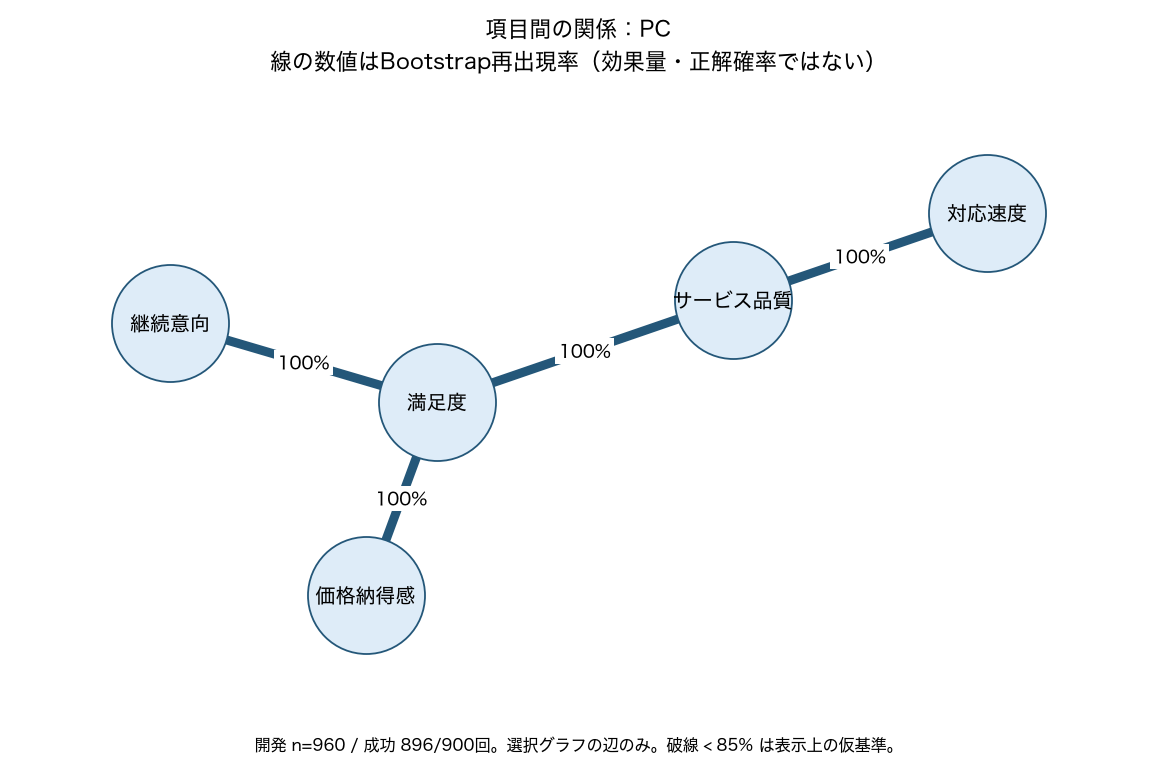

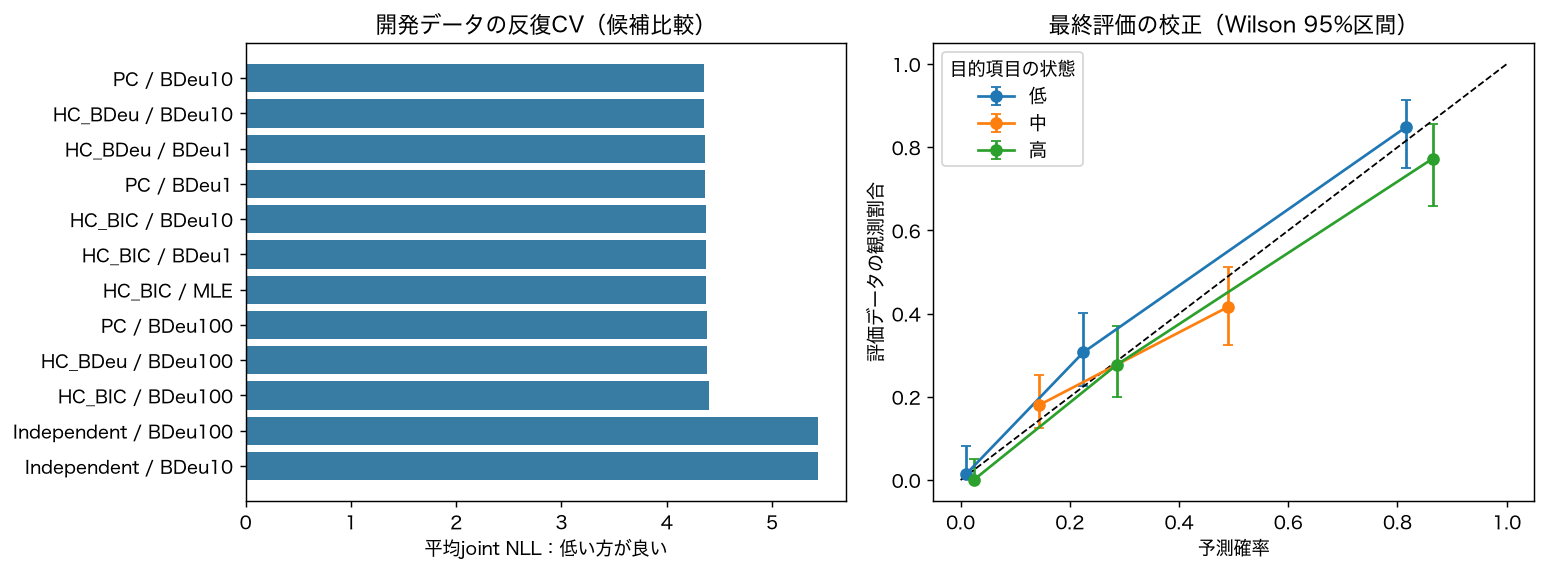

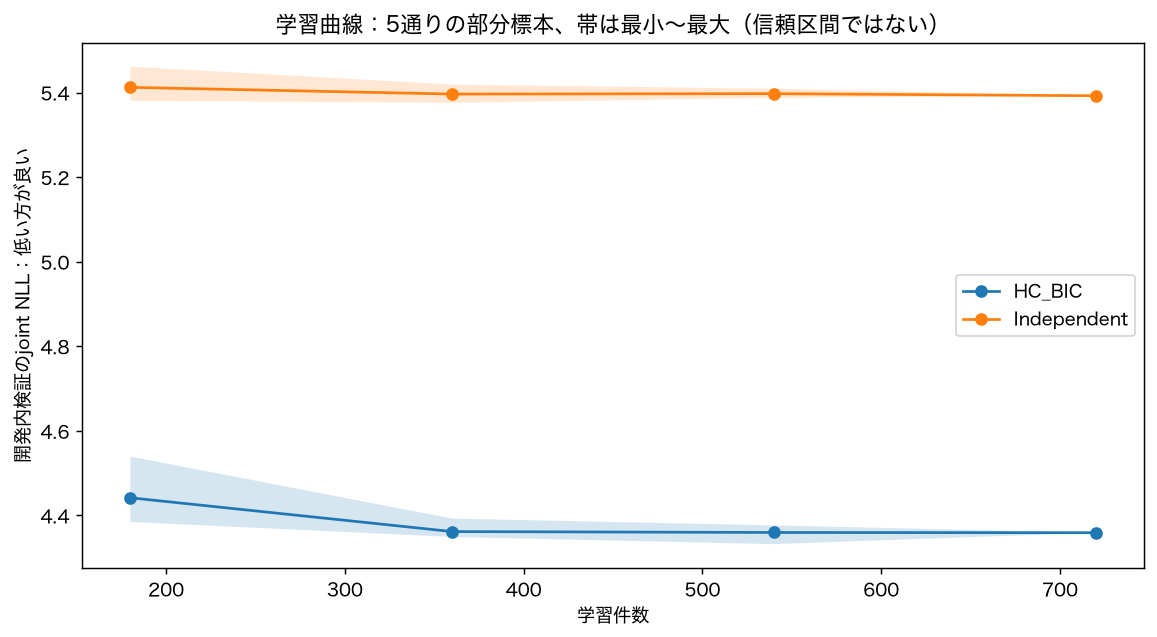

# RESULT：高中低のPython / pgmpy分析

データ：Python生成の人工データ。開発 960 行、最終評価 240 行、5 項目。
生成データの正解ネットワークとの比較はしていません。結果はこの標本・設計での検証です。

## 1. 構造と選択過程
開発データの反復CVで選んだ候補は **PC / BDeu10**。
最良の開発CV平均joint NLLは 4.3549。小さい方が未観測行に高い確率を割り当てています。
候補を選んだ同じCV値には選択による楽観があり、下のnested CVと最終評価を別に示します。

| algorithm | parameter | failed_folds | mean_nll | repeat_min | repeat_max |
| --- | --- | --- | --- | --- | --- |
| PC | BDeu10 | 0 | 4.355 | 4.346 | 4.368 |
| HC_BDeu | BDeu10 | 0 | 4.356 | 4.344 | 4.372 |
| HC_BDeu | BDeu1 | 0 | 4.36 | 4.35 | 4.376 |
| PC | BDeu1 | 0 | 4.365 | 4.354 | 4.383 |
| HC_BIC | BDeu10 | 0 | 4.374 | 4.369 | 4.381 |
| HC_BIC | BDeu1 | 0 | 4.375 | 4.37 | 4.383 |
| HC_BIC | MLE | 0 | 4.375 | 4.37 | 4.383 |
| PC | BDeu100 | 0 | 4.381 | 4.376 | 4.389 |
| HC_BDeu | BDeu100 | 0 | 4.386 | 4.375 | 4.4 |
| HC_BIC | BDeu100 | 0 | 4.405 | 4.401 | 4.41 |
| Independent | BDeu100 | 0 | 5.434 | 5.431 | 5.436 |
| Independent | BDeu10 | 0 | 5.434 | 5.431 | 5.437 |
| Independent | BDeu1 | 0 | 5.434 | 5.431 | 5.437 |
| Independent | MLE | 0 | 5.434 | 5.431 | 5.437 |
| HC_BDeu | MLE | 4 | nan | nan | nan |
| PC | MLE | 6 | nan | nan | nan |

構造スコアは同じ開発標本内で比較します。pgmpyのBICは **高い方が良い**。負の値でも異常ではありません。

| algorithm | edges | parameters | BIC | BDeu_ESS10 |
| --- | --- | --- | --- | --- |
| HC_BIC | 4 | 26 | -4260 | -4242 |
| HC_BDeu | 6 | 50 | -4285 | -4234 |
| PC | 4 | 34 | -4255 | -4226 |
| Independent | 0 | 10 | -5242 | -5232 |

候補選択も内側へ入れたnested CV（外側foldは相関するため、3つを独立標本とした検定は行わない）：

| outer_fold | n | algorithm | parameter | selected_nll | independent_nll |
| --- | --- | --- | --- | --- | --- |
| 0 | 320 | PC | BDeu10 | 4.334 | 5.462 |
| 1 | 320 | HC_BIC | BDeu10 | 4.302 | 5.403 |
| 2 | 320 | PC | BDeu10 | 4.425 | 5.455 |

## 2. 最終評価：独立モデルに対する改善
| selected_nll | independent_nll | improvement | lower95 | upper95 | status |
| --- | --- | --- | --- | --- | --- |
| 4.446 | 5.42 | 0.974 | 0.8204 | 1.139 | ok |

improvement = 独立モデルのNLL − 選択モデルのNLL。正が改善です。
95%区間は最終評価の行をペアで再抽出した区間で、固定済みモデルとi.i.d.行を前提とします。
学習・モデル選択の全不確実性、施設差、将来変化を含みません。業務上必要な改善幅が未定のため、利益や実運用への合格は判定しません。

## 3. エッジを三つの観点で読む
選択手法で再出現率85%以上の候補は 5 本（表示用の仮基準）。
300 回 × 3 seeds / 手法を実行。
同じデータからの再抽出であり、新しい観測や外部再現の件数ではありません。

| algorithm | successful | planned | failed |
| --- | --- | --- | --- |
| HC_BDeu | 900 | 900 | 0 |
| HC_BIC | 900 | 900 | 0 |
| PC | 896 | 900 | 4 |

PCの失敗がある場合、循環などで有効なDAG/CPDAGを得られなかった再標本です。詳細は `bootstrap_errors.csv`。
出現率とMonte Carlo区間は**成功回に条件づけた値**です。失敗回の辺が全て不在／全て存在だったと置く保守的範囲を
`edge_summary.csv` の `failure_bound_lower/upper` に保存します。これは信頼区間ではありません。

| algorithm | a | b | strength | mc_lower95 | mc_upper95 | direction_unresolved | successful | planned |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HC_BIC | サービス品質 | 価格納得感 | 0.2833 | 0.2549 | 0.3136 | 1 | 900 | 900 |
| HC_BIC | サービス品質 | 対応速度 | 1 | 0.9957 | 1 | 0.9967 | 900 | 900 |
| HC_BIC | サービス品質 | 満足度 | 1 | 0.9957 | 1 | 0.7811 | 900 | 900 |
| HC_BIC | サービス品質 | 継続意向 | 0.04444 | 0.03281 | 0.05995 | 1 | 900 | 900 |
| HC_BIC | 価格納得感 | 対応速度 | 0.06 | 0.04628 | 0.07747 | 0.1852 | 900 | 900 |
| HC_BIC | 価格納得感 | 満足度 | 1 | 0.9957 | 1 | 0.7322 | 900 | 900 |
| HC_BIC | 価格納得感 | 継続意向 | 0 | 0 | 0.00425 | nan | 900 | 900 |
| HC_BIC | 対応速度 | 満足度 | 0.1256 | 0.1055 | 0.1488 | 0.9735 | 900 | 900 |
| HC_BIC | 対応速度 | 継続意向 | 0 | 0 | 0.00425 | nan | 900 | 900 |
| HC_BIC | 満足度 | 継続意向 | 1 | 0.9957 | 1 | 0.7811 | 900 | 900 |
| HC_BDeu | サービス品質 | 価格納得感 | 0.7933 | 0.7657 | 0.8185 | 1 | 900 | 900 |
| HC_BDeu | サービス品質 | 対応速度 | 1 | 0.9957 | 1 | 0.9167 | 900 | 900 |
| HC_BDeu | サービス品質 | 満足度 | 1 | 0.9957 | 1 | 0.9133 | 900 | 900 |
| HC_BDeu | サービス品質 | 継続意向 | 0.02111 | 0.01356 | 0.03274 | 0.9474 | 900 | 900 |
| HC_BDeu | 価格納得感 | 対応速度 | 0.1011 | 0.08308 | 0.1225 | 0.7692 | 900 | 900 |
| HC_BDeu | 価格納得感 | 満足度 | 1 | 0.9957 | 1 | 0.89 | 900 | 900 |
| HC_BDeu | 価格納得感 | 継続意向 | 0 | 0 | 0.00425 | nan | 900 | 900 |
| HC_BDeu | 対応速度 | 満足度 | 0.7178 | 0.6875 | 0.7462 | 0.9288 | 900 | 900 |
| HC_BDeu | 対応速度 | 継続意向 | 0.04 | 0.02903 | 0.05488 | 0.1111 | 900 | 900 |
| HC_BDeu | 満足度 | 継続意向 | 1 | 0.9957 | 1 | 0.9133 | 900 | 900 |
| PC | サービス品質 | 価格納得感 | 0.08929 | 0.07233 | 0.1098 | 0.25 | 896 | 900 |
| PC | サービス品質 | 対応速度 | 1 | 0.9957 | 1 | 0.6574 | 896 | 900 |
| PC | サービス品質 | 満足度 | 1 | 0.9957 | 1 | 0.04353 | 896 | 900 |
| PC | サービス品質 | 継続意向 | 0.1964 | 0.1717 | 0.2237 | 0.04545 | 896 | 900 |
| PC | 価格納得感 | 対応速度 | 0.02344 | 0.01538 | 0.03556 | 0.1905 | 896 | 900 |
| PC | 価格納得感 | 満足度 | 1 | 0.9957 | 1 | 0.006696 | 896 | 900 |
| PC | 価格納得感 | 継続意向 | 0.1049 | 0.0865 | 0.1267 | 0.2553 | 896 | 900 |
| PC | 対応速度 | 満足度 | 0.8627 | 0.8386 | 0.8837 | 0.0207 | 896 | 900 |
| PC | 対応速度 | 継続意向 | 0.3192 | 0.2895 | 0.3504 | 0 | 896 | 900 |
| PC | 満足度 | 継続意向 | 1 | 0.9957 | 1 | 0.01116 | 896 | 900 |

strengthは安定性、下表のCramér Vは無条件の関連量、条件付きMIは指定条件の下での関連量です。
同じ『強さ』として読み替えません。方向未確定率はMarkov同値な向きを区別できない割合です。

| a | b | cramer_v | lower95 | upper95 | successful_bootstraps | planned |
| --- | --- | --- | --- | --- | --- | --- |
| サービス品質 | 価格納得感 | 0.1428 | 0.08196 | 0.2434 | 500 | 500 |
| サービス品質 | 対応速度 | 0.6066 | 0.5317 | 0.6887 | 500 | 500 |
| サービス品質 | 満足度 | 0.469 | 0.3942 | 0.5543 | 500 | 500 |
| サービス品質 | 継続意向 | 0.3192 | 0.2457 | 0.4054 | 500 | 500 |
| 価格納得感 | 対応速度 | 0.128 | 0.0768 | 0.225 | 500 | 500 |
| 価格納得感 | 満足度 | 0.2402 | 0.1667 | 0.3358 | 500 | 500 |
| 価格納得感 | 継続意向 | 0.1591 | 0.1064 | 0.2583 | 500 | 500 |
| 対応速度 | 満足度 | 0.3553 | 0.2891 | 0.4422 | 500 | 500 |
| 対応速度 | 継続意向 | 0.2129 | 0.1459 | 0.3047 | 500 | 500 |
| 満足度 | 継続意向 | 0.5424 | 0.4836 | 0.6058 | 500 | 500 |

開発時に固定した全仮説を最終評価で置換検定し、まとめてHolm補正しました。
補正p<0.05の辺は 4 件、モデルが示す条件付き独立性への反証候補は 0 件。
非有意は『独立の証明』『関係なし』ではありません。

| kind | x | y | given | conditional_MI | p | permutations | testable | n | min_stratum_n | p_holm |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| implied_independence | サービス品質 | 価格納得感 | なし | 0.01978 | 0.055 | 1999 | True | 240 | 240 | 0.495 |
| edge | 対応速度 | サービス品質 | なし | 0.3368 | 0.0005 | 1999 | True | 240 | 240 | 0.0065 |
| implied_independence | 対応速度 | 満足度 | サービス品質 | 0.0401 | 0.097 | 1999 | True | 240 | 58 | 0.776 |
| implied_independence | 対応速度 | 継続意向 | サービス品質 | 0.02303 | 0.618 | 1999 | True | 240 | 58 | 1 |
| implied_independence | 対応速度 | 価格納得感 | サービス品質 | 0.01631 | 0.8725 | 1999 | True | 240 | 58 | 1 |
| edge | 満足度 | サービス品質 | 価格納得感 | 0.31 | 0.0005 | 1999 | True | 240 | 68 | 0.0065 |
| implied_independence | 満足度 | 対応速度 | サービス品質 / 価格納得感 | 0.0758 | 0.1045 | 1999 | True | 240 | 15 | 0.776 |
| edge | 満足度 | 価格納得感 | サービス品質 | 0.1412 | 0.0005 | 1999 | True | 240 | 58 | 0.0065 |
| implied_independence | 継続意向 | サービス品質 | 満足度 | 0.01796 | 0.554 | 1999 | True | 240 | 66 | 1 |
| implied_independence | 継続意向 | 対応速度 | 満足度 | 0.01282 | 0.8645 | 1999 | True | 240 | 66 | 1 |
| edge | 継続意向 | 満足度 | なし | 0.3417 | 0.0005 | 1999 | True | 240 | 240 | 0.0065 |
| implied_independence | 継続意向 | 価格納得感 | 満足度 | 0.01278 | 0.849 | 1999 | True | 240 | 66 | 1 |
| implied_independence | 価格納得感 | 対応速度 | なし | 0.01606 | 0.1015 | 1999 | True | 240 | 240 | 0.776 |

## 4. 条件付き確率の精度
全CPT 51 行。未観測の親条件に対応する行は 0 行。
95%信用区間の幅>0.20の行は 4 行。
0.20は点検用の仮閾値であり、必要な精度は業務判断の許容誤差から決めます。
全行は `CPT.csv`。次は区間が広い順の例です。

| node | parents | context | state | n_context | count | probability | lower95 | upper95 | interval_width | prior_fraction | no_data |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 満足度 | サービス品質 / 価格納得感 | 低 / 高 | 中 | 77 | 38 | 0.4912 | 0.3816 | 0.6013 | 0.2197 | 0.01422 | False |
| 満足度 | サービス品質 / 価格納得感 | 低 / 高 | 低 | 77 | 36 | 0.4656 | 0.3568 | 0.5761 | 0.2192 | 0.01422 | False |
| 満足度 | サービス品質 / 価格納得感 | 高 / 低 | 中 | 87 | 49 | 0.5603 | 0.4562 | 0.6618 | 0.2056 | 0.01261 | False |
| 満足度 | サービス品質 / 価格納得感 | 高 / 低 | 高 | 87 | 33 | 0.3787 | 0.2809 | 0.4818 | 0.2009 | 0.01261 | False |
| 満足度 | サービス品質 / 価格納得感 | 低 / 中 | 低 | 90 | 60 | 0.6626 | 0.5629 | 0.7555 | 0.1926 | 0.0122 | False |
| 満足度 | サービス品質 / 価格納得感 | 低 / 中 | 中 | 90 | 29 | 0.3224 | 0.2309 | 0.4212 | 0.1903 | 0.0122 | False |
| 満足度 | サービス品質 / 価格納得感 | 中 / 高 | 中 | 111 | 58 | 0.5206 | 0.4284 | 0.6122 | 0.1838 | 0.009911 | False |
| 満足度 | サービス品質 / 価格納得感 | 中 / 高 | 高 | 111 | 51 | 0.4582 | 0.3673 | 0.5506 | 0.1833 | 0.009911 | False |
| 満足度 | サービス品質 / 価格納得感 | 高 / 中 | 高 | 113 | 75 | 0.6605 | 0.5715 | 0.7441 | 0.1726 | 0.009737 | False |
| 満足度 | サービス品質 / 価格納得感 | 高 / 中 | 中 | 113 | 36 | 0.3187 | 0.2368 | 0.4067 | 0.1699 | 0.009737 | False |
| 満足度 | サービス品質 / 価格納得感 | 中 / 低 | 中 | 128 | 78 | 0.607 | 0.5217 | 0.6892 | 0.1675 | 0.008606 | False |
| 満足度 | サービス品質 / 価格納得感 | 中 / 低 | 低 | 128 | 45 | 0.3514 | 0.2717 | 0.4355 | 0.1637 | 0.008606 | False |

区間は選択した構造とBDeu事前分布を固定した各セルの周辺信用区間です。全セル同時95%区間ではなく、構造選択の不確実性も含みません。

## 5. 確率の出力と分布適合
目的項目の診断（指定項目がある場合のみ。他項目をすべて観測した条件付き確率）：

| model | log_loss | multiclass_brier |
| --- | --- | --- |
| selected | 0.7716 | 0.4624 |
| independent | 1.102 | 0.6695 |

多クラスBrierは3状態の二乗誤差の和で0〜2、log lossは0以上、いずれも低い方が良い。
校正図は `validation.png`、件数付き表は `calibration.csv`。

| max_abs_probability_gap | simulation_reference95 | diagnostic_p | simulations |
| --- | --- | --- | --- |
| 0.04927 | 0.07817 | 0.658 | 499 |

分布適合はペアの状態割合に対する最大ずれです。simulation_reference95は固定モデルから同件数を生成したときの95%参考点。
diagnostic_pは固定モデルのシミュレーション診断で、全モデルの正しさを保証する検定ではありません。高次の関係は別の点検が必要です。

## 6. 業務への提示判断
**分析手続きの実行と説明は可能ですが、実業務への採用可否は未判定です。**
人工データから業務利益を推定できません。実データの測定品質、代表性、独立単位、最小重要差、損失・取得コスト、外部／時間検証、公平性、監視責任の合意が必要です。
失敗した候補や不支持の結果も表に残しています。CVの詳細とエラーメッセージは `cv_detail.csv`。
プレゼンテーションの順序と話し方はNotebookの16章を参照してください。


In [22]:
plot_results(selected_graph, selected, edge_summary, cv_summary, cpt,
             calibration, learning_curve, OUT)
for filename in ['network.png', 'validation.png', 'learning_curve.png']:
    display(Image(filename=str(OUT / filename)))

result_text = write_result(OUT, DATA_SOURCE, development, holdout, selected,
    cv_summary, structure_scores, nested, holdout_loss, edge_summary, cpt,
    conditional_results, effects, target_metrics, global_fit, CONFIG)
display(Markdown(result_text))

## 15. 業務部門へ提示するための検証範囲と残課題

BNのあらゆる業務に共通する一つの合格規格はありません。以下は統計的説明と実務判断のための確認表です。
NIST AI RMFは任意のリスク管理枠組みで、BNのスコアの合格点を定める規格ではありません。[NIST公式](https://www.nist.gov/itl/ai-risk-management-framework)

|確認事項|今回の実施・出力|実データで追加する判断|
|---|---|---|
|1. 意思決定と対象|説明対象と基準モデルを固定|誰が何を決めるか、利益・損失・取得費用|
|2. 母集団と代表性|人工データと明示|抽出方法、非回答、選択バイアス、適用外の対象|
|3. 独立単位|独立した行を仮定|同一顧客・施設・時系列を考慮した分割・再抽出|
|4. 測定の信頼性|3状態・欠測・定数列を確認|高中低の定義、評価者間一致、期間ごとの定義変更|
|5. 欠測と前処理|不正入力は停止|欠測機構、補完と感度分析。補完は学習fold内|
|6. 情報漏洩|開発／最終評価分離|予測時点、対象者の重複、未来の情報|
|7. 構造と複雑さ|HC2スコア・PC・独立モデル、親数感度|業務上不可能な関係の事前制約、探索初期値・項目選択感度|
|8. 選択の楽観|nested CVと固定holdout|最終評価を見た仕様変更には新しい評価標本|
|9. パラメータの根拠|全CPT、件数、信用区間|重要条件の必要精度と追加収集|
|10. 事前分布|MLE/BDeu1/10/100比較|専門知識による事前分布の妥当性と感度|
|11. エッジの安定性|3手法×3seed×300回|行独立でない場合の群Bootstrap。外部データの再現|
|12. 関連量|Cramér Vと条件付きMI|実務的な意味のある差、条件間の比較対象|
|13. 独立性仮定と検定|開発固定仮説をholdoutで置換検定|希少条件・検出力・高次依存を補足|
|14. 多重性|検定族を固定、Holm補正|新規探索は別族として都合よく追加せず再計画|
|15. 分布適合|ペア最大ずれの固定モデル診断|高次のずれ、潜在要因、モデルクラスの不足|
|16. 予測確率の適合|三状態log loss/Brier/校正|利用可能な項目だけの将来予測、実際の損失|
|17. 感度と必要標本数|ESS・親数・閾値・学習量|最小重要差に対するパワー／精度設計。未実施と明示|
|18. サブグループ・公平性|関連メタデータなし、未検証|部門・地域・属性別の性能と不利益。少数群の区間|
|19. 外部／時間妥当性|未検証|別期間・別拠点・別組織で固定モデルを評価|
|20. 再現性・監視と責任|seed・分割・版・データ指紋を保存|更新条件、監視頻度、承認者、ドリフト時の対応|

### 検定を追加する判断
- **差が実務上無視できると主張する場合**：事前の同等性マージンを設定し、同等性検定や区間評価を行う。p>.05で代替しない。
- **現行より悪くなければ採用する場合**：非劣性マージンと誤判定費用を事前に設定する。
- **サンプル数を決める場合**：最小重要差・想定分布・多重性・集団構造を使ったシミュレーション型パワー設計、または必要なCPT区間幅に基づく精度設計。今回は必要業務差が未定なので正式なパワー設計は未実施。
- **施策の効果を主張する場合**：この関連分析とは別に実験や因果推論の設計が必要。本Notebookは操作の効果を推定していない。

「有意にするまで回す」「良いseedだけを採用する」ことはしません。反復数と主張を先に固定し、失敗・非有意・手法依存も説明します。

## 16. プレゼンテーションは何をどの順に示すか

本編は約10枚、各ページを **一文の結論・一つの図表・読み取り・限界** で構成します。
結論は実行後のRESULTに合わせて更新し、数字の良い部分だけを選びません。

|枚|伝えること|使う図表／話し方|
|---|---|---|
|1|今回どこまで分かったか|安定した点・不確かな点・次の判断依頼を3行。人工データと明示|
|2|誰のどの項目の関係か|行単位、件数、高中低の意味、開発／評価の分割|
|3|関係のまとまり|network.png。「線の数値は再出現率で、効果の大きさではない」|
|4|別の標本にも説明が届くか|nested_cv.csvとholdout_loss.csv。独立モデルとの差と区間|
|5|条件ごとの確率をどこまで言えるか|CPT.csvの代表3条件。低中高の3確率、件数、信用区間|
|6|『強さ』の三つの意味|edge_summary / pairwise_effects / conditional_testsを並べ、安定性・量・検定を分離|
|7|予測確率と実際は一致するか|validation.pngの校正。少数帯の不確実性も見せる|
|8|仕様とデータ量に依存しないか|learning_curve.pngと親数／ESS感度。不支持の例も併記|
|9|言える範囲と言えない範囲|検証範囲20項目。代表性・公平性・外部妥当性・実務差は未確認|
|10|次に決めたいこと|必要な精度、最小重要差、対象期間・拠点、追加データ、責任者と期限|

### 話す際の具体例
- 「この親条件の集団で『高』である推定確率は○%。根拠はn件で、固定モデルでの95%信用区間は○〜○%です。」
- 「900回の再抽出の○%でこの辺が出ました。この標本における安定性で、真実の確率○%という意味ではありません。」
- 「独立モデルより評価損失が○nat/行小さくなりました。区間は○〜○ですが、実務上必要な差はまだ合意していません。」
- 「この仮説には反証が見つかりました／今回の件数では反証を検出できませんでした。」

### 誤解を避ける脚注
確率は%で、確率の差はポイントで表す。NLLを正解率と呼ばない。信用区間・評価Bootstrap区間・Monte Carlo区間を区別する。
p値は0と丸めない。件数、反復数、比較基準、補正族、対象期間を添える。補正pだけで採用を決めない。
同じデータのseed変更、RとPythonの一致を「独立に再現した」と呼ばない。

### 付録と次の運用
全候補のスコア、全CPT、全辺、全検定と失敗、設定、バージョン、分割ID、データ指紋を付録に残す。
実運用では状態割合、重要条件の件数、損失と校正、関係の変動、対象外の入力を監視する。
頻回な再検定の誤警報を考慮し、確認頻度・再学習条件・承認責任を事前に決める。

## 17. 実行記録・保存・再実行

以下で設定・モデルのCPD・データとコードのSHA-256を保存します。pickleは使わず、人が読めるJSONを残します。
Python版はR版のフォルダを変更しません。ライブラリの仕様差、PCの向きの補完、探索の同点処理によって、同じ標本でもグラフの向きが一致しない場合があります。

このNotebookをRun Allすると、14章の動的な要約、`results/RESULT.md`、本章の `manifest.json` がすべて同じ実行の結果で更新されます。
同じフォルダで再実行すると `results/` は上書きされます。別の分析として残す場合はフォルダごとコピーしてから実行してください。

In [23]:
cpd_export = [{
    'variable': cpd.variable, 'variables': cpd.variables,
    'cardinality': cpd.cardinality.tolist(), 'values': cpd.values.tolist(),
    'state_names': cpd.state_names,
} for cpd in selected_model.get_cpds()]
(OUT/'model_cpds.json').write_text(json.dumps(cpd_export, ensure_ascii=False, indent=2), encoding='utf-8')

def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

manifest = {
    'completed_at': datetime.now().astimezone().isoformat(), 'python': sys.version,
    'executable': sys.executable, 'versions': versions, 'config': CONFIG,
    'data_source': DATA_SOURCE, 'data_sha256': file_sha256(OUT/'input_data.csv'),
    'split_sha256': file_sha256(OUT/'split_assignment.csv'),
    # 関数はこのNotebook内で定義しているため、Notebookファイル自体の指紋を記録（実行開始前に保存された状態）
    'notebook_sha256': {p.name: file_sha256(p) for p in sorted(Path('.').glob('*.ipynb'))},
    'selected_algorithm': selected.algorithm, 'selected_parameter': selected.parameter,
    'cv_fits': len(cv_detail), 'bootstrap_attempts': len(CONFIG['bootstrap_algorithms'])*
        len(CONFIG['bootstrap_seeds'])*CONFIG['bootstrap_repetitions'],
    'bootstrap_failures': len(bootstrap_errors),
}
(OUT/'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print('保存完了:', OUT.resolve())
print('RESULT.mdとNotebookの動的表示が今回の実行結果です。')

保存完了: /Users/user01/agent_dir/bayesian_network_demo_20261124191042_chatgpt_integrated/results
RESULT.mdとNotebookの動的表示が今回の実行結果です。


## 18. 実装検証（旧 validation_checks.py）

小さな人工表で、入力dfを変更しないこと、状態の並び、孤立ノード、joint確率の正規化、事後件数、CPTの正規化、未観測条件でのMLEの扱い、0確率の損失、Holm補正、CPDAG同値を検査します。
さらに `results/` の保存物（CV件数、辺の方向割合、Monte Carlo区間、CPT、検定p値、分割）の整合性を確認します。すべて通ると `PASS` が表示され、失敗すると `AssertionError` で止まります。

In [24]:
run_checks()

PASS: input preservation, state alignment, isolated nodes, exact joint normalization,
posterior counts, CPT normalization, unseen-context MLE, zero-probability loss,
Holm adjustment, CPDAG equivalence, and saved-output integrity checks.


## 一次資料と調査時点

調査日：2026-11-24。使用APIはインストール済みpgmpy 1.1.2のソースと実行で確認しました。
オンラインの最新ドキュメントが別版へ進む場合があります。環境版はmanifest.jsonを優先してください。

- [pgmpy：構造学習](https://pgmpy.org/api/structure_learning.html) — HCとPCなどの実装。
- [pgmpy：構造スコア](https://pgmpy.org/api/structure_score.html) — BICとBDeu。
- [pgmpy：パラメータ推定](https://pgmpy.org/guides/parameter_estimation.html) — 最尤推定とベイズ推定。
- [pgmpy：DAG/CPDAG](https://pgmpy.org/api/generated/base/pgmpy.base.DAG.html) — 同値類の表現。
- [scikit-learn：nested CV](https://sklearn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html) — 選択と評価の分離。
- [ASA：p値に関する声明](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf) — 有意性、重要性、判断の区別。
- [SciPy：多重比較](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html) — FDRとFWERの区別、BH/BYの前提。
- [SciPy：Cramér V](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html) — 関連量の定義。
- [NIST：AI RMF](https://www.nist.gov/itl/ai-risk-management-framework) — 任意のリスク管理・評価の枠組み。BN固有の採点規格ではない。

0.85/0.95の辺出現率、CPT区間幅0.20は本演習の表示設定です。出典が普遍的な業務合格点として推奨している値ではありません。